# 🎥 Video Subtitle Understanding and Summarization
## Topic 17 – NLP Project | IUH 2026
### Phần 3: Hiện thực | Phần 4: Đánh giá kết quả
---

In [1]:
# ====================== CELL 1: CÀI ĐẶT THƯ VIỆN ======================
import subprocess, sys

packages = [
    "evaluate", "rouge_score", "bert_score",
    "transformers>=4.40.0", "datasets", "accelerate",
    "sentencepiece", "nltk", "matplotlib", "seaborn", "tqdm"
]
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + packages, check=True)

import os, json, re, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter

import torch
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)

from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM,
    Seq2SeqTrainingArguments, Seq2SeqTrainer,
    DataCollatorForSeq2Seq, EarlyStoppingCallback
)
from datasets import Dataset, DatasetDict
import evaluate

print(f"✅ PyTorch: {torch.__version__}")
print(f"✅ GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"✅ VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB" if torch.cuda.is_available() else "")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.3 MB/s eta 0:00:00
✅ PyTorch: 2.10.0+cu128
✅ GPU: Tesla T4
✅ VRAM: 15.6 GB


In [2]:
import os

BASE_DIR = "/kaggle/input/datasets/prasadmagdum/nlpproject/VT-SSum-main"

print(os.listdir(BASE_DIR))

['README.md', 'test', 'train', 'dev']


## 📂 Phần 3.1 – Load & Khám phá Dữ liệu (VT-SSum Dataset)

In [3]:
# ====================== CELL 2: LOAD VT-SSum DATASET ======================

import os
import json
import pandas as pd
from tqdm.auto import tqdm

# =========================================================
# LOAD FUNCTION
# =========================================================

def load_vtsssum(data_dir, max_samples=None):

    records = []

    files = [f for f in os.listdir(data_dir) if f.endswith(".json")]

    if max_samples:
        files = files[:max_samples]

    for fname in tqdm(files, desc=f"Loading {os.path.basename(data_dir)}"):

        try:

            file_path = os.path.join(data_dir, fname)

            with open(file_path, encoding="utf-8") as f:
                item = json.load(f)

            # =================================================
            # CLEAN TRANSCRIPT
            # segmentation -> list transcript segments
            # =================================================

            segments = item.get("segmentation", [])

            transcript_sentences = []

            for segment in segments:

                if isinstance(segment, list):

                    for sent in segment:

                        if isinstance(sent, str):
                            transcript_sentences.append(sent)

                elif isinstance(segment, str):

                    transcript_sentences.append(segment)

            transcript = " ".join(transcript_sentences).strip()

            # =================================================
            # CLEAN SUMMARY
            # lấy sentence có label = 1
            # =================================================

            summary_parts = []

            summ_data = item.get("summarization", {})

            for clip_data in summ_data.values():

                for row in clip_data.get("summarization_data", []):

                    if row.get("label") == 1:

                        sent = row.get("sent", "").strip()

                        if sent:
                            summary_parts.append(sent)

            summary = " ".join(summary_parts).strip()

            # =================================================
            # FILTER
            # =================================================

            if len(transcript.split()) >= 20 and len(summary.split()) >= 3:

                records.append({
                    "transcript": transcript,
                    "summary": summary
                })

        except Exception as e:
            pass

    print(f"✅ Loaded {len(records):,} samples from {data_dir}")

    return pd.DataFrame(records)


# =========================================================
# DATASET PATHS
# =========================================================

BASE_DIR = "/kaggle/input/datasets/prasadmagdum/nlpproject/VT-SSum-main"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR   = os.path.join(BASE_DIR, "dev")
TEST_DIR  = os.path.join(BASE_DIR, "test")


# =========================================================
# LOAD DATASET
# =========================================================

train_df = load_vtsssum(TRAIN_DIR)

val_df = load_vtsssum(VAL_DIR)

test_df = load_vtsssum(TEST_DIR, max_samples=500)


# =========================================================
# LIMIT DATASET SIZE
# =========================================================

train_df = (
    train_df.sample(
        min(6000, len(train_df)),
        random_state=42
    )
    .reset_index(drop=True)
)

val_df = (
    val_df.sample(
        min(600, len(val_df)),
        random_state=42
    )
    .reset_index(drop=True)
)

test_df = (
    test_df.sample(
        min(400, len(test_df)),
        random_state=42
    )
    .reset_index(drop=True)
)


# =========================================================
# SHOW RESULT
# =========================================================

print("\n📊 Dataset Split:")

print(f"  Train : {len(train_df):,} samples")
print(f"  Val   : {len(val_df):,} samples")
print(f"  Test  : {len(test_df):,} samples")

print(f"  Total : {len(train_df)+len(val_df)+len(test_df):,} samples")


# =========================================================
# PREVIEW
# =========================================================

print("\n================ SAMPLE ==================")

print("\nTranscript:")
print(train_df.iloc[0]["transcript"][:1000])

print("\nSummary:")
print(train_df.iloc[0]["summary"])

Loading train:   0%|          | 0/7692 [00:00<?, ?it/s]

✅ Loaded 7,692 samples from /kaggle/input/datasets/prasadmagdum/nlpproject/VT-SSum-main/train


Loading dev:   0%|          | 0/962 [00:00<?, ?it/s]

✅ Loaded 962 samples from /kaggle/input/datasets/prasadmagdum/nlpproject/VT-SSum-main/dev


Loading test:   0%|          | 0/500 [00:00<?, ?it/s]

✅ Loaded 500 samples from /kaggle/input/datasets/prasadmagdum/nlpproject/VT-SSum-main/test

📊 Dataset Split:
  Train : 6,000 samples
  Val   : 600 samples
  Test  : 400 samples
  Total : 7,000 samples

================ SAMPLE ==================

Transcript:
So thank you very much, Mr. Chairman, thank you also to the ICC Committee for having invited me. I will report on the expert program and elaborate on its lessons learned. So here is a presentation and layout. I will quickly review the objectives of this in flight research program and then only similarly elaborate on the tree associated ICC programs. Because after my presentation, both professors, even a fan, characterful present the details of their ICC activities. So I will also elaborate in towards the end. Some spinoffs which I have started already as good examples of this ICC activities and then conclude on some lessons learned. So first of all, while I was expert. Started and it came back from flight expertise and flight testin

## 📊 Phần 3.2 – Phân tích Khám phá Dữ liệu (EDA)

/tmp/ipykernel_57/1372188446.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1,1].boxplot(split_data, labels=["Train","Val","Test"], patch_artist=True,
/tmp/ipykernel_57/1372188446.py:55: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/1372188446.py:56: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig("eda_analysis.png", dpi=150, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


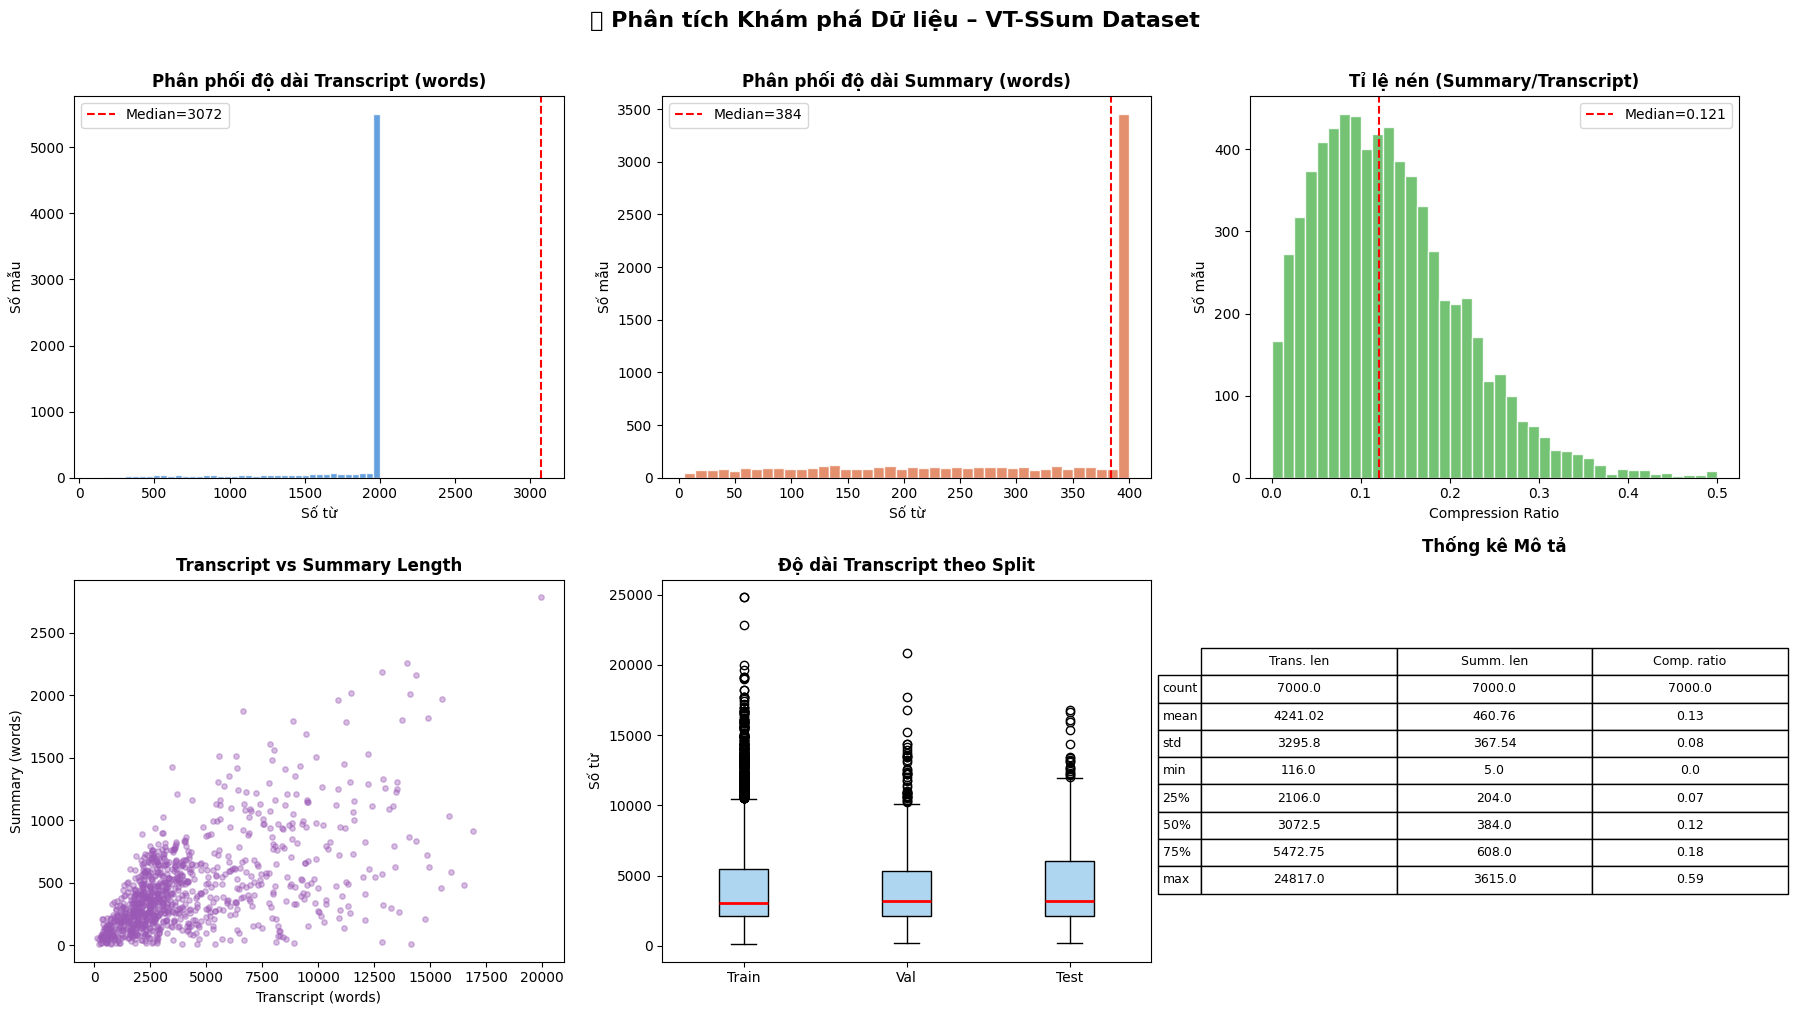

✅ EDA hoàn tất


In [4]:
# ====================== CELL 3: EDA – PHÂN TÍCH DỮ LIỆU ======================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("📊 Phân tích Khám phá Dữ liệu – VT-SSum Dataset", fontsize=16, fontweight="bold", y=1.01)

all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
all_df["trans_len"]  = all_df["transcript"].apply(lambda x: len(x.split()))
all_df["summ_len"]   = all_df["summary"].apply(lambda x: len(x.split()))
all_df["comp_ratio"] = all_df["summ_len"] / all_df["trans_len"]

# 1. Phân phối độ dài transcript
axes[0,0].hist(all_df["trans_len"].clip(upper=2000), bins=40, color="#4A90D9", edgecolor="white", alpha=0.85)
axes[0,0].set_title("Phân phối độ dài Transcript (words)", fontsize=12, fontweight="bold")
axes[0,0].set_xlabel("Số từ"); axes[0,0].set_ylabel("Số mẫu")
axes[0,0].axvline(all_df["trans_len"].median(), color="red", linestyle="--", label=f"Median={all_df['trans_len'].median():.0f}")
axes[0,0].legend()

# 2. Phân phối độ dài summary
axes[0,1].hist(all_df["summ_len"].clip(upper=400), bins=40, color="#E07B54", edgecolor="white", alpha=0.85)
axes[0,1].set_title("Phân phối độ dài Summary (words)", fontsize=12, fontweight="bold")
axes[0,1].set_xlabel("Số từ"); axes[0,1].set_ylabel("Số mẫu")
axes[0,1].axvline(all_df["summ_len"].median(), color="red", linestyle="--", label=f"Median={all_df['summ_len'].median():.0f}")
axes[0,1].legend()

# 3. Tỉ lệ nén
axes[0,2].hist(all_df["comp_ratio"].clip(upper=0.5), bins=40, color="#5CB85C", edgecolor="white", alpha=0.85)
axes[0,2].set_title("Tỉ lệ nén (Summary/Transcript)", fontsize=12, fontweight="bold")
axes[0,2].set_xlabel("Compression Ratio"); axes[0,2].set_ylabel("Số mẫu")
axes[0,2].axvline(all_df["comp_ratio"].median(), color="red", linestyle="--", label=f"Median={all_df['comp_ratio'].median():.3f}")
axes[0,2].legend()

# 4. Scatter: transcript vs summary length
sample_plot = all_df.sample(min(1000, len(all_df)), random_state=42)
axes[1,0].scatter(sample_plot["trans_len"], sample_plot["summ_len"], alpha=0.4, s=15, color="#9B59B6")
axes[1,0].set_title("Transcript vs Summary Length", fontsize=12, fontweight="bold")
axes[1,0].set_xlabel("Transcript (words)"); axes[1,0].set_ylabel("Summary (words)")

# 5. Boxplot 3 split
split_data = [train_df["transcript"].apply(lambda x: len(x.split())),
              val_df["transcript"].apply(lambda x: len(x.split())),
              test_df["transcript"].apply(lambda x: len(x.split()))]
bp = axes[1,1].boxplot(split_data, labels=["Train","Val","Test"], patch_artist=True,
                        boxprops=dict(facecolor="#AED6F1"), medianprops=dict(color="red",linewidth=2))
axes[1,1].set_title("Độ dài Transcript theo Split", fontsize=12, fontweight="bold")
axes[1,1].set_ylabel("Số từ")

# 6. Thống kê tổng hợp
stats = all_df[["trans_len","summ_len","comp_ratio"]].describe().round(2)
axes[1,2].axis("off")
table = axes[1,2].table(cellText=stats.values, rowLabels=stats.index,
                         colLabels=["Trans. len","Summ. len","Comp. ratio"],
                         cellLoc="center", loc="center")
table.auto_set_font_size(False); table.set_fontsize(9); table.scale(1.2, 1.5)
axes[1,2].set_title("Thống kê Mô tả", fontsize=12, fontweight="bold", pad=20)

plt.tight_layout()
plt.savefig("eda_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ EDA hoàn tất")


## 🗺️ Phần 3.2b – Sơ đồ Tổng quát Pipeline Hệ thống

/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 128249 (\N{VIDEO CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 129529 (\N{BROOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:63: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/2681722937.py:64: UserWarning: Glyph 128249 (\N{VIDEO CAMERA}) missing from font(s) DejaVu Sans.
  plt.savefig("pipeline_diagram.png", dpi=150, bbox_inches="tight")
/tm

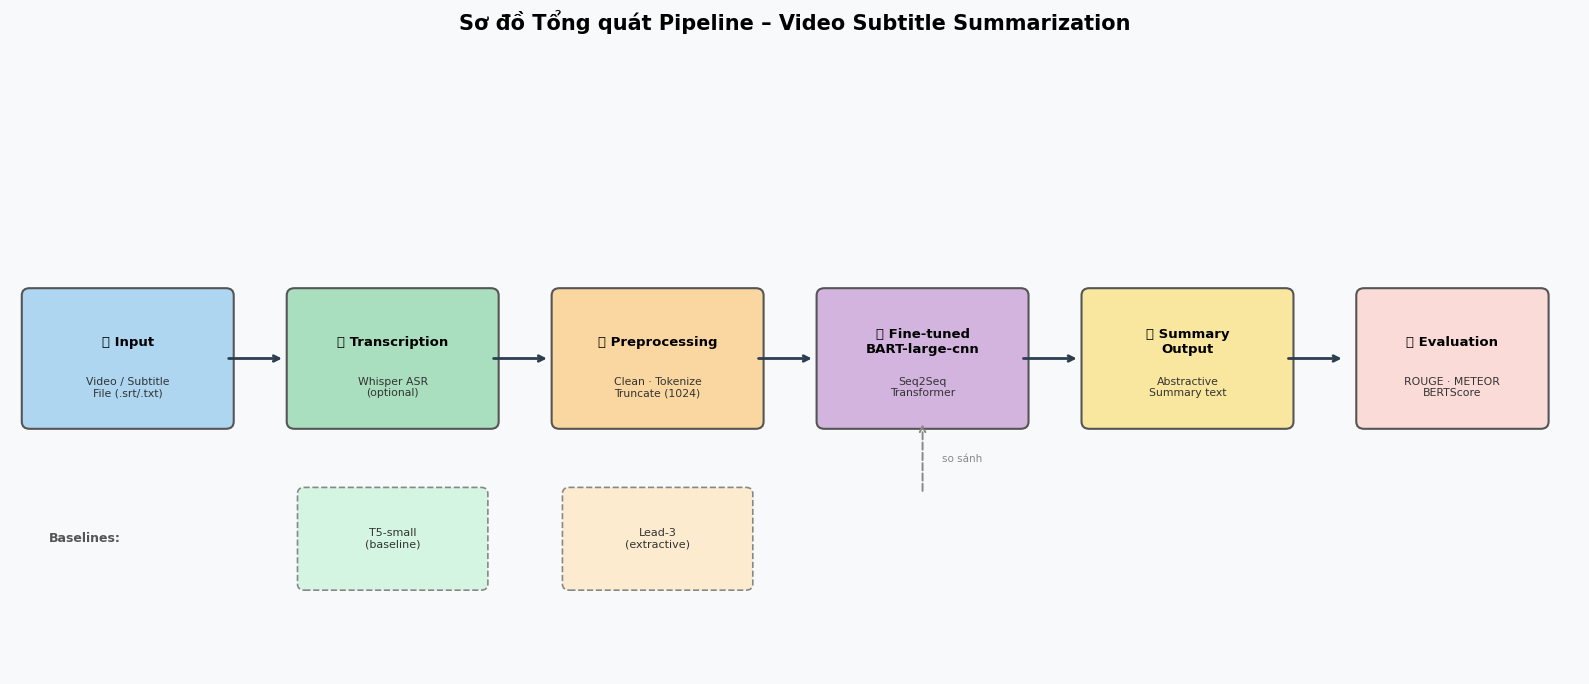

✅ Đã vẽ sơ đồ tổng quát pipeline


In [5]:
# ====================== SƠ ĐỒ TỔNG QUÁT PIPELINE ======================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 7))
ax.set_xlim(0, 16)
ax.set_ylim(0, 7)
ax.axis("off")
fig.patch.set_facecolor("#F8F9FA")
ax.set_facecolor("#F8F9FA")

fig.suptitle("Sơ đồ Tổng quát Pipeline – Video Subtitle Summarization",
             fontsize=15, fontweight="bold", y=0.97)

# ── Định nghĩa các block ──────────────────────────────────────────────
blocks = [
    # (x_center, y_center, width, height, label, sublabel, color)
    (1.2,  3.5, 2.0, 1.4, "📹 Input",         "Video / Subtitle\nFile (.srt/.txt)", "#AED6F1"),
    (3.9,  3.5, 2.0, 1.4, "🔤 Transcription", "Whisper ASR\n(optional)", "#A9DFBF"),
    (6.6,  3.5, 2.0, 1.4, "🧹 Preprocessing", "Clean · Tokenize\nTruncate (1024)", "#FAD7A0"),
    (9.3,  3.5, 2.0, 1.4, "🤖 Fine-tuned\nBART-large-cnn", "Seq2Seq\nTransformer", "#D2B4DE"),
    (12.0, 3.5, 2.0, 1.4, "📝 Summary\nOutput",  "Abstractive\nSummary text", "#F9E79F"),
    (14.7, 3.5, 1.8, 1.4, "📊 Evaluation",    "ROUGE · METEOR\nBERTScore", "#FADBD8"),
]

for (cx, cy, w, h, lbl, sub, col) in blocks:
    rect = FancyBboxPatch((cx - w/2, cy - h/2), w, h,
                          boxstyle="round,pad=0.08",
                          linewidth=1.5, edgecolor="#555",
                          facecolor=col, zorder=3)
    ax.add_patch(rect)
    ax.text(cx, cy + 0.18, lbl, ha="center", va="center",
            fontsize=9.5, fontweight="bold", zorder=4)
    ax.text(cx, cy - 0.32, sub, ha="center", va="center",
            fontsize=7.8, color="#333", zorder=4)

# ── Mũi tên nối các block ─────────────────────────────────────────────
arrow_xs = [2.2, 4.9, 7.6, 10.3, 13.0]
for ax_x in arrow_xs:
    ax.annotate("", xy=(ax_x + 0.6, 3.5), xytext=(ax_x, 3.5),
                arrowprops=dict(arrowstyle="->", color="#2C3E50",
                                lw=2.0), zorder=5)

# ── Baseline box bên dưới ─────────────────────────────────────────────
for (cx, lbl, col) in [(3.9, "T5-small\n(baseline)", "#D5F5E3"),
                        (6.6, "Lead-3\n(extractive)", "#FDEBD0")]:
    rect = FancyBboxPatch((cx - 0.9, 1.0), 1.8, 1.0,
                          boxstyle="round,pad=0.07",
                          linewidth=1.2, edgecolor="#888",
                          facecolor=col, linestyle="--", zorder=3)
    ax.add_patch(rect)
    ax.text(cx, 1.5, lbl, ha="center", va="center",
            fontsize=8, color="#333", zorder=4)

ax.text(0.4, 1.5, "Baselines:", fontsize=9, fontweight="bold",
        va="center", color="#555")
ax.annotate("", xy=(9.3, 2.8), xytext=(9.3, 2.0),
            arrowprops=dict(arrowstyle="->", color="#888", lw=1.4,
                            linestyle="dashed"), zorder=5)
ax.text(9.5, 2.35, "so sánh", fontsize=7.5, color="#888")

plt.tight_layout()
plt.savefig("pipeline_diagram.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Đã vẽ sơ đồ tổng quát pipeline")


## 🤖 Phần 3.3 – Load Model BART & Tiền xử lý

In [6]:
# ====================== CELL 4: LOAD BART-LARGE-CNN ======================
# Model chính: facebook/bart-large-cnn
# Fine-tune cho bài toán Video Transcript Summarization

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from datasets import Dataset, DatasetDict
import torch

# =========================================================
# MODEL CONFIG
# =========================================================

MODEL_NAME = "facebook/bart-large-cnn"

MAX_INPUT  = 1024
MAX_TARGET = 256

print(f"🔄 Đang load tokenizer & model: {MODEL_NAME}")

# =========================================================
# LOAD TOKENIZER & MODEL
# =========================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

# Gradient checkpointing để tiết kiệm VRAM
model.gradient_checkpointing_enable()

model = model.to(DEVICE)

# =========================================================
# MODEL INFO
# =========================================================

n_params = sum(p.numel() for p in model.parameters()) / 1e6

print(f"✅ Model: {MODEL_NAME}")
print(f"   Số tham số: {n_params:.0f}M")
print(f"   VRAM đang dùng: {torch.cuda.memory_allocated()/1e9:.2f} GB")


# =========================================================
# PREPROCESS FUNCTION
# =========================================================

def preprocess(examples):

    # Input text
    inputs = [
        "summarize: " + t
        for t in examples["transcript"]
    ]

    # Target summary
    targets = examples["summary"]

    # =====================================================
    # TOKENIZE INPUT
    # =====================================================

    model_inputs = tokenizer(
        inputs,
        max_length=MAX_INPUT,
        truncation=True,
        padding="max_length"
    )

    # =====================================================
    # TOKENIZE TARGET
    # =====================================================

    labels = tokenizer(
        text_target=targets,
        max_length=MAX_TARGET,
        truncation=True,
        padding="max_length"
    )

    # =====================================================
    # IGNORE PAD TOKEN IN LOSS
    # =====================================================

    label_ids = [
        [
            (token if token != tokenizer.pad_token_id else -100)
            for token in label
        ]
        for label in labels["input_ids"]
    ]

    model_inputs["labels"] = label_ids

    return model_inputs


# =========================================================
# CONVERT TO HF DATASET
# =========================================================

ds = DatasetDict({

    "train": Dataset.from_pandas(
        train_df[["transcript", "summary"]]
    ),

    "val": Dataset.from_pandas(
        val_df[["transcript", "summary"]]
    ),

    "test": Dataset.from_pandas(
        test_df[["transcript", "summary"]]
    ),
})


# =========================================================
# TOKENIZATION
# =========================================================

tok_ds = ds.map(
    preprocess,
    batched=True,
    batch_size=32,
    remove_columns=["transcript", "summary"],
    desc="Tokenizing"
)


# =========================================================
# DONE
# =========================================================

print("\n✅ Tokenization xong:")

print(f"   Train tokens: {len(tok_ds['train'])}")
print(f"   Val tokens  : {len(tok_ds['val'])}")
print(f"   Test tokens : {len(tok_ds['test'])}")

🔄 Đang load tokenizer & model: facebook/bart-large-cnn


config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

... (4 outputs left out)

Tokenizing:   0%|          | 0/6000 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/600 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/400 [00:00<?, ? examples/s]


✅ Tokenization xong:
   Train tokens: 6000
   Val tokens  : 600
   Test tokens : 400


## 🏗️ Phần 3.3b – Kiến trúc Mô hình BART & Tham số

/tmp/ipykernel_57/3596563760.py:121: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig("architecture_params.png", dpi=150, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


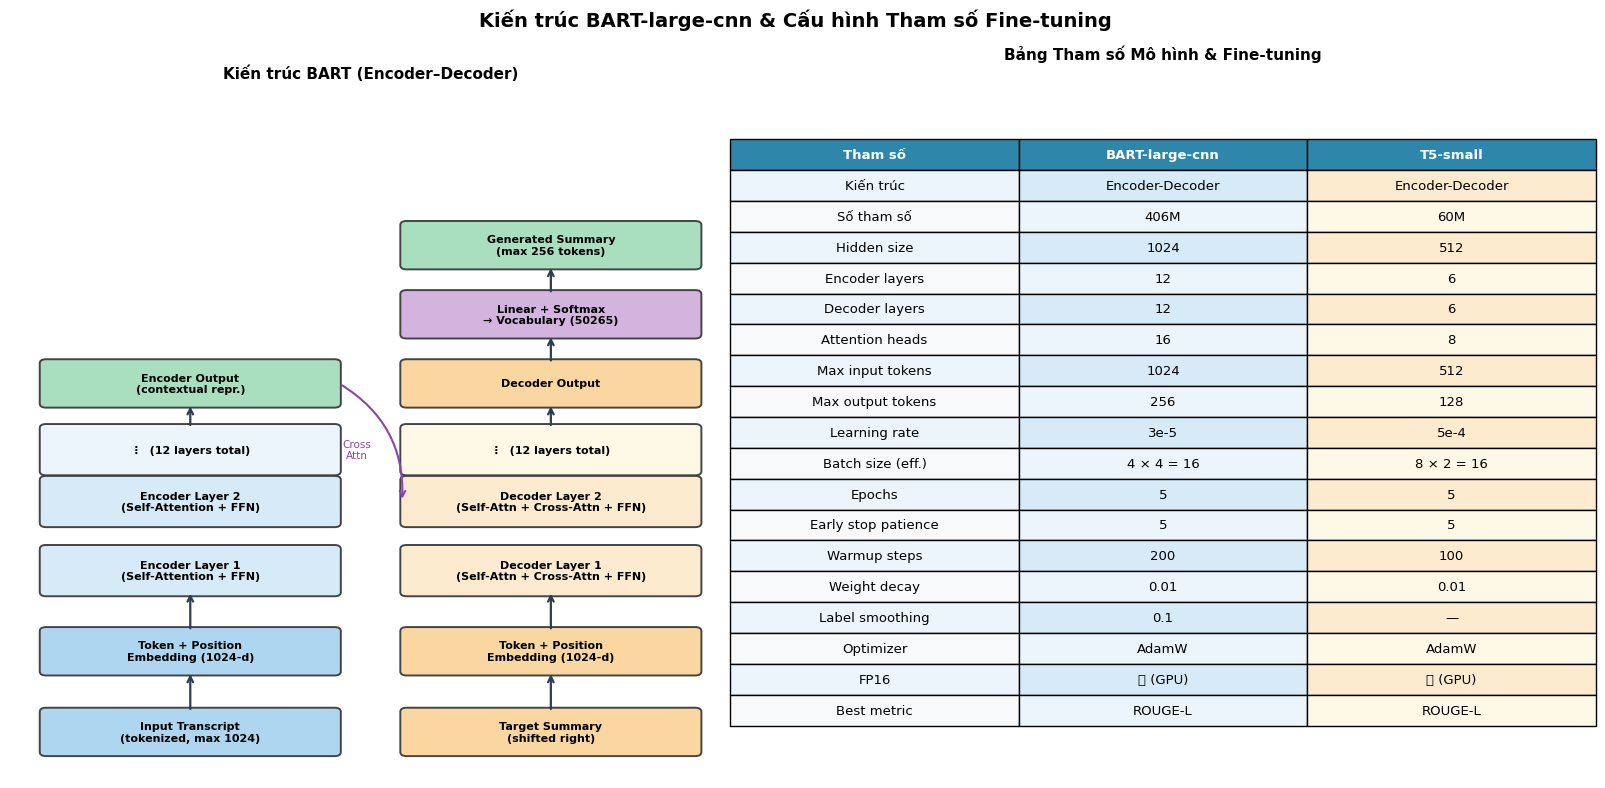

✅ Đã vẽ kiến trúc BART và bảng tham số


In [7]:
# ====================== KIẾN TRÚC BART + THAM SỐ ======================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("Kiến trúc BART-large-cnn & Cấu hình Tham số Fine-tuning",
             fontsize=14, fontweight="bold")

# ── LEFT: BART architecture diagram ──────────────────────────────────
ax = axes[0]
ax.set_xlim(0, 8); ax.set_ylim(0, 12); ax.axis("off")
ax.set_facecolor("#FDFEFE")

def box(ax, cx, cy, w, h, txt, col, fs=9):
    r = FancyBboxPatch((cx-w/2, cy-h/2), w, h,
                       boxstyle="round,pad=0.07",
                       facecolor=col, edgecolor="#444", lw=1.4, zorder=3)
    ax.add_patch(r)
    ax.text(cx, cy, txt, ha="center", va="center",
            fontsize=fs, fontweight="bold", zorder=4, multialignment="center")

def arr(ax, x1,y1,x2,y2):
    ax.annotate("", xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle="->", color="#2C3E50", lw=1.6), zorder=5)

# Encoder stack
box(ax, 2, 0.8, 3.2, 0.7, "Input Transcript\n(tokenized, max 1024)", "#AED6F1", 8)
arr(ax, 2,1.15, 2,1.85)
box(ax, 2, 2.2, 3.2, 0.7, "Token + Position\nEmbedding (1024-d)", "#AED6F1", 8)
arr(ax, 2,2.55, 2,3.25)
for i, (lbl, cy) in enumerate([
    ("Encoder Layer 1\n(Self-Attention + FFN)", 3.6),
    ("Encoder Layer 2\n(Self-Attention + FFN)", 4.8),
    ("  ⋮  (12 layers total)  ", 5.7),
], 1):
    col = "#D6EAF8" if i < 3 else "#EBF5FB"
    box(ax, 2, cy, 3.2, 0.75, lbl, col, 8)
    if i < 3: arr(ax, 2, cy-0.37, 2, cy+0.38-0.75)
arr(ax, 2,6.08, 2,6.5)
box(ax, 2, 6.85, 3.2, 0.7, "Encoder Output\n(contextual repr.)", "#A9DFBF", 8)

# Decoder stack
box(ax, 6, 0.8, 3.2, 0.7, "Target Summary\n(shifted right)", "#FAD7A0", 8)
arr(ax, 6,1.15, 6,1.85)
box(ax, 6, 2.2, 3.2, 0.7, "Token + Position\nEmbedding (1024-d)", "#FAD7A0", 8)
arr(ax, 6,2.55, 6,3.25)
for i, (lbl, cy) in enumerate([
    ("Decoder Layer 1\n(Self-Attn + Cross-Attn + FFN)", 3.6),
    ("Decoder Layer 2\n(Self-Attn + Cross-Attn + FFN)", 4.8),
    ("  ⋮  (12 layers total)  ", 5.7),
], 1):
    col = "#FDEBD0" if i < 3 else "#FEF9E7"
    box(ax, 6, cy, 3.2, 0.75, lbl, col, 8)
    if i < 3: arr(ax, 6, cy-0.37, 6, cy+0.38-0.75)
arr(ax, 6,6.08, 6,6.5)
box(ax, 6, 6.85, 3.2, 0.7, "Decoder Output", "#FAD7A0", 8)
arr(ax, 6,7.2, 6,7.7)
box(ax, 6, 8.05, 3.2, 0.7, "Linear + Softmax\n→ Vocabulary (50265)", "#D2B4DE", 8)
arr(ax, 6,8.4, 6,8.9)
box(ax, 6, 9.25, 3.2, 0.7, "Generated Summary\n(max 256 tokens)", "#A9DFBF", 8)

# Cross attention arrows encoder→decoder
ax.annotate("", xy=(4.35, 4.8), xytext=(3.65, 6.85),
            arrowprops=dict(arrowstyle="->", color="#8E44AD", lw=1.5,
                            connectionstyle="arc3,rad=-0.3"), zorder=5)
ax.text(3.85, 5.7, "Cross\nAttn", fontsize=7.5, color="#8E44AD",
        ha="center", va="center")

ax.set_title("Kiến trúc BART (Encoder–Decoder)", fontsize=11, fontweight="bold")

# ── RIGHT: Hyperparameter table ───────────────────────────────────────
ax2 = axes[1]
ax2.axis("off")

params = [
    ["Tham số",                  "BART-large-cnn",   "T5-small"],
    ["Kiến trúc",                "Encoder-Decoder",  "Encoder-Decoder"],
    ["Số tham số",               "406M",             "60M"],
    ["Hidden size",              "1024",             "512"],
    ["Encoder layers",           "12",               "6"],
    ["Decoder layers",           "12",               "6"],
    ["Attention heads",          "16",               "8"],
    ["Max input tokens",         "1024",             "512"],
    ["Max output tokens",        "256",              "128"],
    ["Learning rate",            "3e-5",             "5e-4"],
    ["Batch size (eff.)",        "4 × 4 = 16",       "8 × 2 = 16"],
    ["Epochs",                   "5",                "5"],
    ["Early stop patience",      "5",                "5"],
    ["Warmup steps",             "200",              "100"],
    ["Weight decay",             "0.01",             "0.01"],
    ["Label smoothing",          "0.1",              "—"],
    ["Optimizer",                "AdamW",            "AdamW"],
    ["FP16",                     "✅ (GPU)",          "✅ (GPU)"],
    ["Best metric",              "ROUGE-L",          "ROUGE-L"],
]

col_colors = [["#2E86AB","#2E86AB","#2E86AB"]] + \
             [["#EBF5FB","#D6EAF8","#FDEBD0"] if i%2==0
              else ["#F8F9FA","#EBF5FB","#FEF9E7"]
              for i in range(len(params)-1)]

tbl = ax2.table(
    cellText=params[1:],
    colLabels=params[0],
    cellLoc="center",
    loc="center",
    cellColours=col_colors[1:]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1.2, 1.65)

for j in range(3):
    tbl[(0,j)].set_facecolor("#2E86AB")
    tbl[(0,j)].set_text_props(color="white", fontweight="bold")

ax2.set_title("Bảng Tham số Mô hình & Fine-tuning", fontsize=11, fontweight="bold", pad=20)

plt.tight_layout()
plt.savefig("architecture_params.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Đã vẽ kiến trúc BART và bảng tham số")


## 🚀 Phần 3.4 – Huấn luyện BART (Fine-tuning)

## 🔄 Phần 3.4b – Lưu đồ Giải thuật Fine-tuning BART

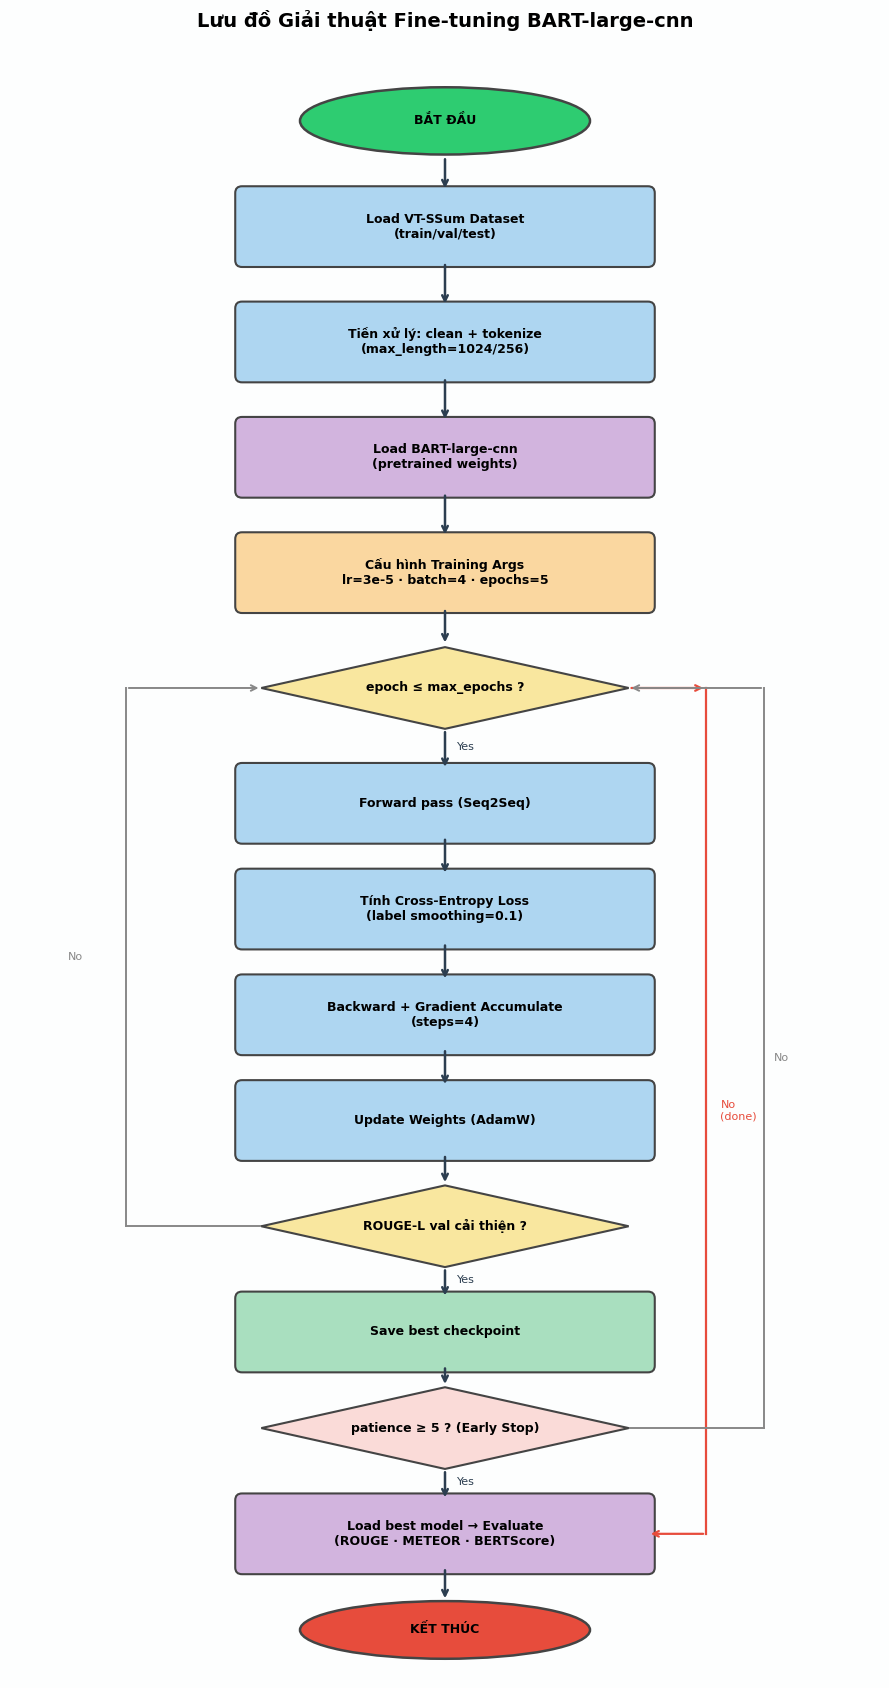

✅ Đã vẽ lưu đồ giải thuật fine-tuning


In [8]:
# ====================== LƯU ĐỒ GIẢI THUẬT FINE-TUNING ======================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 17))
ax.set_xlim(0, 9)
ax.set_ylim(0, 17)
ax.axis("off")
fig.patch.set_facecolor("#FDFEFE")
fig.suptitle("Lưu đồ Giải thuật Fine-tuning BART-large-cnn",
             fontsize=14, fontweight="bold", y=0.99)

def draw_box(ax, cx, cy, w, h, text, shape="rect", color="#AED6F1", fontsize=9):
    if shape == "diamond":
        dx, dy = w/2, h/2
        diamond = plt.Polygon(
            [[cx, cy+dy],[cx+dx, cy],[cx, cy-dy],[cx-dx, cy]],
            closed=True, facecolor=color, edgecolor="#444", linewidth=1.5, zorder=3)
        ax.add_patch(diamond)
    elif shape == "oval":
        ell = mpatches.Ellipse((cx, cy), w, h,
                               facecolor=color, edgecolor="#444", linewidth=1.8, zorder=3)
        ax.add_patch(ell)
    else:
        rect = FancyBboxPatch((cx-w/2, cy-h/2), w, h,
                              boxstyle="round,pad=0.07",
                              facecolor=color, edgecolor="#444",
                              linewidth=1.5, zorder=3)
        ax.add_patch(rect)
    ax.text(cx, cy, text, ha="center", va="center",
            fontsize=fontsize, fontweight="bold", zorder=4,
            wrap=True, multialignment="center")

def arrow(ax, x1, y1, x2, y2, label="", color="#2C3E50"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color=color, lw=1.8), zorder=5)
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx+0.12, my, label, fontsize=8, color=color)

CX = 4.5
steps = [
    (CX, 16.2, 3.0, 0.7, "BẮT ĐẦU",                         "oval",    "#2ECC71"),
    (CX, 15.1, 4.2, 0.7, "Load VT-SSum Dataset\n(train/val/test)", "rect", "#AED6F1"),
    (CX, 13.9, 4.2, 0.7, "Tiền xử lý: clean + tokenize\n(max_length=1024/256)", "rect", "#AED6F1"),
    (CX, 12.7, 4.2, 0.7, "Load BART-large-cnn\n(pretrained weights)", "rect", "#D2B4DE"),
    (CX, 11.5, 4.2, 0.7, "Cấu hình Training Args\nlr=3e-5 · batch=4 · epochs=5", "rect", "#FAD7A0"),
    (CX, 10.3, 3.8, 0.85,"epoch ≤ max_epochs ?",              "diamond", "#F9E79F"),
    (CX,  9.1, 4.2, 0.7, "Forward pass (Seq2Seq)",            "rect",    "#AED6F1"),
    (CX,  8.0, 4.2, 0.7, "Tính Cross-Entropy Loss\n(label smoothing=0.1)", "rect", "#AED6F1"),
    (CX,  6.9, 4.2, 0.7, "Backward + Gradient Accumulate\n(steps=4)",     "rect",    "#AED6F1"),
    (CX,  5.8, 4.2, 0.7, "Update Weights (AdamW)",            "rect",    "#AED6F1"),
    (CX,  4.7, 3.8, 0.85,"ROUGE-L val cải thiện ?",           "diamond", "#F9E79F"),
    (CX,  3.6, 4.2, 0.7, "Save best checkpoint",             "rect",    "#A9DFBF"),
    (CX,  2.6, 3.8, 0.85,"patience ≥ 5 ? (Early Stop)",      "diamond", "#FADBD8"),
    (CX,  1.5, 4.2, 0.7, "Load best model → Evaluate\n(ROUGE · METEOR · BERTScore)", "rect", "#D2B4DE"),
    (CX,  0.5, 3.0, 0.6, "KẾT THÚC",                         "oval",    "#E74C3C"),
]

ys = [s[1] for s in steps]
for s in steps:
    draw_box(ax, s[0], s[1], s[2], s[3], s[4], s[5], s[6])

# Arrows straight down
pairs = [(0,1),(1,2),(2,3),(3,4),(4,5)]
for a,b in pairs:
    arrow(ax, CX, ys[a]-steps[a][3]/2-0.02, CX, ys[b]+steps[b][3]/2+0.02)

# epoch yes
arrow(ax, CX, ys[5]-0.43, CX, ys[6]+0.35, "Yes")
for a,b in [(6,7),(7,8),(8,9)]:
    arrow(ax, CX, ys[a]-0.35, CX, ys[b]+0.35)

# epoch no → end (right side loop back)
ax.annotate("", xy=(7.2, ys[5]), xytext=(CX+1.9, ys[5]),
            arrowprops=dict(arrowstyle="->", color="#E74C3C", lw=1.6))
ax.plot([7.2, 7.2], [ys[5], ys[13]+0.0], color="#E74C3C", lw=1.6)
ax.annotate("", xy=(CX+2.1, ys[13]), xytext=(7.2, ys[13]),
            arrowprops=dict(arrowstyle="->", color="#E74C3C", lw=1.6))
ax.text(7.35, (ys[5]+ys[13])/2, "No\n(done)", fontsize=8,
        color="#E74C3C", va="center")

# step 9 → 10
arrow(ax, CX, ys[9]-0.35, CX, ys[10]+0.43)
# diamond 10 yes
arrow(ax, CX, ys[10]-0.43, CX, ys[11]+0.35, "Yes")
# diamond 10 no (no improvement – skip save, loop back to epoch check via right)
ax.plot([CX-1.9, 1.2], [ys[10], ys[10]], color="#888", lw=1.4)
ax.plot([1.2, 1.2], [ys[10], ys[5]], color="#888", lw=1.4)
ax.annotate("", xy=(CX-1.9, ys[5]), xytext=(1.2, ys[5]),
            arrowprops=dict(arrowstyle="->", color="#888", lw=1.4))
ax.text(0.6, (ys[10]+ys[5])/2, "No", fontsize=8, color="#888", va="center")

# 11 → 12
arrow(ax, CX, ys[11]-0.35, CX, ys[12]+0.43)
# early stop yes
arrow(ax, CX, ys[12]-0.43, CX, ys[13]+0.35, "Yes")
# early stop no → loop back to epoch
ax.plot([CX+1.9, 7.8], [ys[12], ys[12]], color="#888", lw=1.4)
ax.plot([7.8, 7.8], [ys[12], ys[5]], color="#888", lw=1.4)
ax.annotate("", xy=(CX+1.9, ys[5]), xytext=(7.8, ys[5]),
            arrowprops=dict(arrowstyle="->", color="#888", lw=1.4))
ax.text(7.9, (ys[12]+ys[5])/2, "No", fontsize=8, color="#888", va="center")

# 13 → 14
arrow(ax, CX, ys[13]-0.35, CX, ys[14]+0.3)

plt.tight_layout()
plt.savefig("flowchart_finetuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Đã vẽ lưu đồ giải thuật fine-tuning")


In [9]:
# ====================== CELL 5: TRAINING BART ======================

import numpy as np
import evaluate

from transformers import (
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback
)

# =========================================================
# LOAD METRICS
# =========================================================

rouge_metric  = evaluate.load("rouge")
meteor_metric = evaluate.load("meteor")


# =========================================================
# COMPUTE METRICS
# =========================================================

def compute_metrics(eval_pred):

    preds, labels = eval_pred

    # Decode predictions
    decoded_preds = tokenizer.batch_decode(
        preds,
        skip_special_tokens=True
    )

    # Replace -100 before decoding labels
    labels = np.where(
        labels != -100,
        labels,
        tokenizer.pad_token_id
    )

    decoded_labels = tokenizer.batch_decode(
        labels,
        skip_special_tokens=True
    )

    # Normalize whitespace
    decoded_preds = [
        pred.strip()
        for pred in decoded_preds
    ]

    decoded_labels = [
        label.strip()
        for label in decoded_labels
    ]

    # =====================================================
    # ROUGE
    # =====================================================

    rouge_res = rouge_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )

    # =====================================================
    # METEOR
    # =====================================================

    meteor_res = meteor_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels
    )

    return {

        "ROUGE-1": round(rouge_res["rouge1"] * 100, 2),

        "ROUGE-2": round(rouge_res["rouge2"] * 100, 2),

        "ROUGE-L": round(rouge_res["rougeL"] * 100, 2),

        "METEOR": round(meteor_res["meteor"] * 100, 2),
    }


# =========================================================
# TRAINING ARGUMENTS
# =========================================================

training_args = Seq2SeqTrainingArguments(

    output_dir="./bart_finetuned",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=3e-5,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=4,

    weight_decay=0.01,

    num_train_epochs=5,

    warmup_steps=200,

    predict_with_generate=True,

    generation_max_length=MAX_TARGET,

    fp16=torch.cuda.is_available(),

    save_total_limit=2,

    load_best_model_at_end=True,

    metric_for_best_model="ROUGE-L",

    greater_is_better=True,

    report_to="none",

    logging_steps=50,

    dataloader_num_workers=2,

    label_smoothing_factor=0.1,
)


# =========================================================
# DATA COLLATOR
# =========================================================

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    pad_to_multiple_of=8
)


# =========================================================
# TRAINER
# =========================================================

trainer = Seq2SeqTrainer(

    model=model,

    args=training_args,

    train_dataset=tok_ds["train"],

    eval_dataset=tok_ds["val"],

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5
        )
    ],
)


# =========================================================
# TRAIN
# =========================================================

print("🚀 Bắt đầu fine-tuning BART-large-cnn...")

print(f"   Epochs       : {training_args.num_train_epochs}")

print(
    f"   Batch size   : "
    f"{training_args.per_device_train_batch_size} × "
    f"{training_args.gradient_accumulation_steps} = "
    f"{training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps} effective"
)

print(f"   Learning rate: {training_args.learning_rate}")

trainer.train()


# =========================================================
# SAVE BEST MODEL
# =========================================================

trainer.save_model("./bart_best")

tokenizer.save_pretrained("./bart_best")

print("\n✅ Training hoàn tất!")

print("📁 Model saved at: ./bart_best")

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


🚀 Bắt đầu fine-tuning BART-large-cnn...
   Epochs       : 5
   Batch size   : 4 × 4 = 16 effective
   Learning rate: 3e-05


Epoch,Training Loss,Validation Loss,Rouge-1,Rouge-2,Rouge-l,Meteor
1,23.743137,2.867670,50.310000,26.180000,31.140000,37.720000
2,22.411580,2.816031,51.650000,27.780000,32.400000,39.580000
3,21.803872,2.796041,51.910000,28.130000,32.970000,40.330000
4,21.170332,2.787331,52.360000,28.890000,33.600000,40.750000
5,20.838203,2.786473,52.360000,28.870000,33.570000,40.720000


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Training hoàn tất!
📁 Model saved at: ./bart_best


/tmp/ipykernel_57/3278260758.py:29: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_57/3278260758.py:30: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


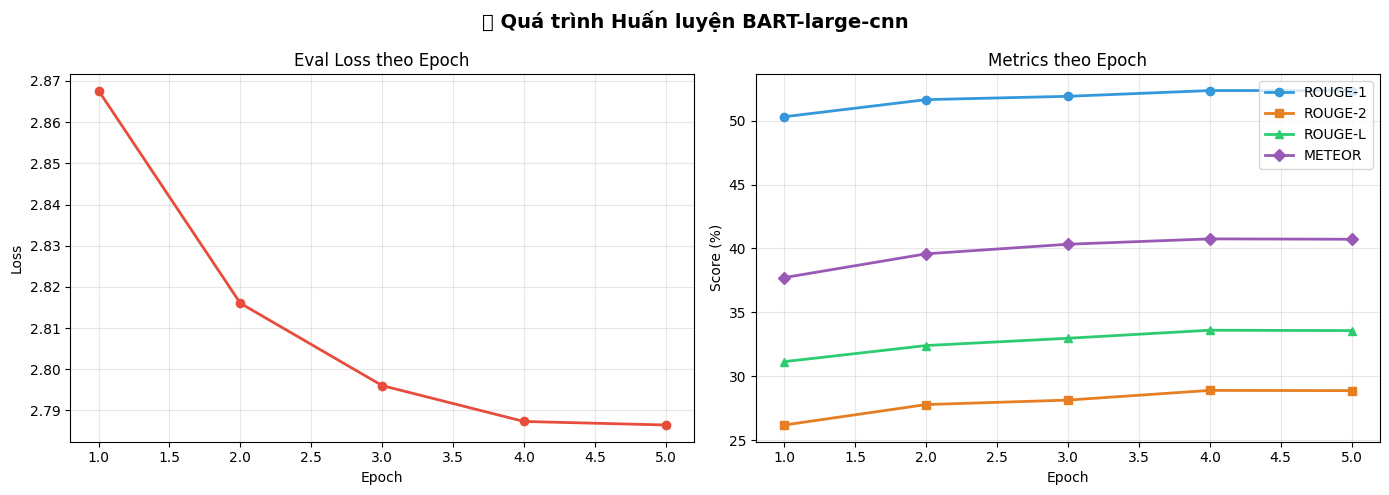

✅ Đã vẽ training curves


In [10]:
# ====================== CELL 6: VẼ BIỂU ĐỒ TRAINING ======================
log_history = trainer.state.log_history

train_logs = [l for l in log_history if "loss" in l and "eval_loss" not in l]
eval_logs  = [l for l in log_history if "eval_loss" in l]

if eval_logs:
    epochs      = [l["epoch"]       for l in eval_logs]
    eval_losses = [l["eval_loss"]   for l in eval_logs]
    rouge1_vals = [l.get("eval_ROUGE-1", 0) for l in eval_logs]
    rouge2_vals = [l.get("eval_ROUGE-2", 0) for l in eval_logs]
    rougel_vals = [l.get("eval_ROUGE-L", 0) for l in eval_logs]
    meteor_vals = [l.get("eval_METEOR",  0) for l in eval_logs]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("📈 Quá trình Huấn luyện BART-large-cnn", fontsize=14, fontweight="bold")

    axes[0].plot(epochs, eval_losses, "o-", color="#E74C3C", linewidth=2, markersize=6)
    axes[0].set_title("Eval Loss theo Epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, rouge1_vals, "o-", label="ROUGE-1", color="#3498DB", linewidth=2)
    axes[1].plot(epochs, rouge2_vals, "s-", label="ROUGE-2", color="#E67E22", linewidth=2)
    axes[1].plot(epochs, rougel_vals, "^-", label="ROUGE-L", color="#2ECC71", linewidth=2)
    axes[1].plot(epochs, meteor_vals, "D-", label="METEOR",  color="#9B59B6", linewidth=2)
    axes[1].set_title("Metrics theo Epoch"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score (%)")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("✅ Đã vẽ training curves")
else:
    print("⚠️ Chưa có eval logs (kiểm tra lại eval_strategy)")


## ⚖️ Phần 4.1 – Cài đặt các Baseline để So sánh

In [11]:
# ====================== CELL 7: BASELINE MODELS ======================
# 1. BART-large-cnn (fine-tuned)
# 2. T5-small (baseline)
# 3. Lead-3 baseline

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback
)

from nltk.tokenize import sent_tokenize

# =========================================================
# LOAD T5-SMALL
# =========================================================

T5_NAME = "t5-small"

print(f"🔄 Load T5-small...")

t5_tokenizer = AutoTokenizer.from_pretrained(T5_NAME)

t5_model = (
    AutoModelForSeq2SeqLM
    .from_pretrained(T5_NAME)
    .to(DEVICE)
)


# =========================================================
# PREPROCESS FUNCTION
# =========================================================

def preprocess_t5(examples):

    inputs = [
        "summarize: " + t
        for t in examples["transcript"]
    ]

    targets = examples["summary"]

    # =====================================================
    # TOKENIZE INPUT
    # =====================================================

    model_inputs = t5_tokenizer(
        inputs,
        max_length=512,
        truncation=True,
        padding="max_length"
    )

    # =====================================================
    # TOKENIZE TARGET
    # =====================================================

    labels = t5_tokenizer(
        text_target=targets,
        max_length=128,
        truncation=True,
        padding="max_length"
    )

    # =====================================================
    # IGNORE PAD TOKEN
    # =====================================================

    model_inputs["labels"] = [
        [
            (
                token
                if token != t5_tokenizer.pad_token_id
                else -100
            )
            for token in label
        ]
        for label in labels["input_ids"]
    ]

    return model_inputs


# =========================================================
# TOKENIZE DATASET
# =========================================================

tok_ds_t5 = ds.map(
    preprocess_t5,
    batched=True,
    batch_size=32,
    remove_columns=["transcript", "summary"],
    desc="T5 Tokenizing"
)


# =========================================================
# COMPUTE METRICS
# =========================================================

def compute_metrics_t5(eval_pred):

    preds, labels = eval_pred

    decoded_preds = t5_tokenizer.batch_decode(
        preds,
        skip_special_tokens=True
    )

    labels = np.where(
        labels != -100,
        labels,
        t5_tokenizer.pad_token_id
    )

    decoded_labels = t5_tokenizer.batch_decode(
        labels,
        skip_special_tokens=True
    )

    decoded_preds = [
        pred.strip()
        for pred in decoded_preds
    ]

    decoded_labels = [
        label.strip()
        for label in decoded_labels
    ]

    # =====================================================
    # ROUGE
    # =====================================================

    rouge_res = rouge_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )

    # =====================================================
    # METEOR
    # =====================================================

    meteor_res = meteor_metric.compute(
        predictions=decoded_preds,
        references=decoded_labels
    )

    return {

        "ROUGE-1": round(rouge_res["rouge1"] * 100, 2),

        "ROUGE-2": round(rouge_res["rouge2"] * 100, 2),

        "ROUGE-L": round(rouge_res["rougeL"] * 100, 2),

        "METEOR": round(meteor_res["meteor"] * 100, 2),
    }


# =========================================================
# TRAINING ARGUMENTS
# =========================================================

t5_args = Seq2SeqTrainingArguments(

    output_dir="./t5_finetuned",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=5e-4,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    gradient_accumulation_steps=2,

    weight_decay=0.01,

    num_train_epochs=5,

    warmup_steps=100,

    predict_with_generate=True,

    generation_max_length=128,

    fp16=torch.cuda.is_available(),

    save_total_limit=1,

    load_best_model_at_end=True,

    metric_for_best_model="ROUGE-L",

    greater_is_better=True,

    report_to="none",

    logging_steps=100,
)


# =========================================================
# DATA COLLATOR
# =========================================================

dc_t5 = DataCollatorForSeq2Seq(
    tokenizer=t5_tokenizer,
    model=t5_model,
    pad_to_multiple_of=8
)


# =========================================================
# TRAINER
# =========================================================

t5_trainer = Seq2SeqTrainer(

    model=t5_model,

    args=t5_args,

    train_dataset=tok_ds_t5["train"],

    eval_dataset=tok_ds_t5["val"],

    processing_class=t5_tokenizer,

    data_collator=dc_t5,

    compute_metrics=compute_metrics_t5,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5
        )
    ],
)


# =========================================================
# TRAIN T5
# =========================================================

print("🚀 Fine-tuning T5-small...")

t5_trainer.train()

t5_trainer.save_model("./t5_best")

print("✅ T5-small training xong!")


# =========================================================
# LEAD-3 BASELINE
# =========================================================

def lead3_summarize(text, n=3):

    sentences = sent_tokenize(text)

    return " ".join(sentences[:n]).strip()


print("\n✅ Đã định nghĩa Lead-3 baseline")

print("   → Lead-3: chọn 3 câu đầu làm summary")
print("   → Không cần train")

🔄 Load T5-small...


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ T5-small training xong!

✅ Đã định nghĩa Lead-3 baseline
   → Lead-3: chọn 3 câu đầu làm summary
   → Không cần train


## 📉 Phần 4.1b – So sánh Training Curves BART vs T5

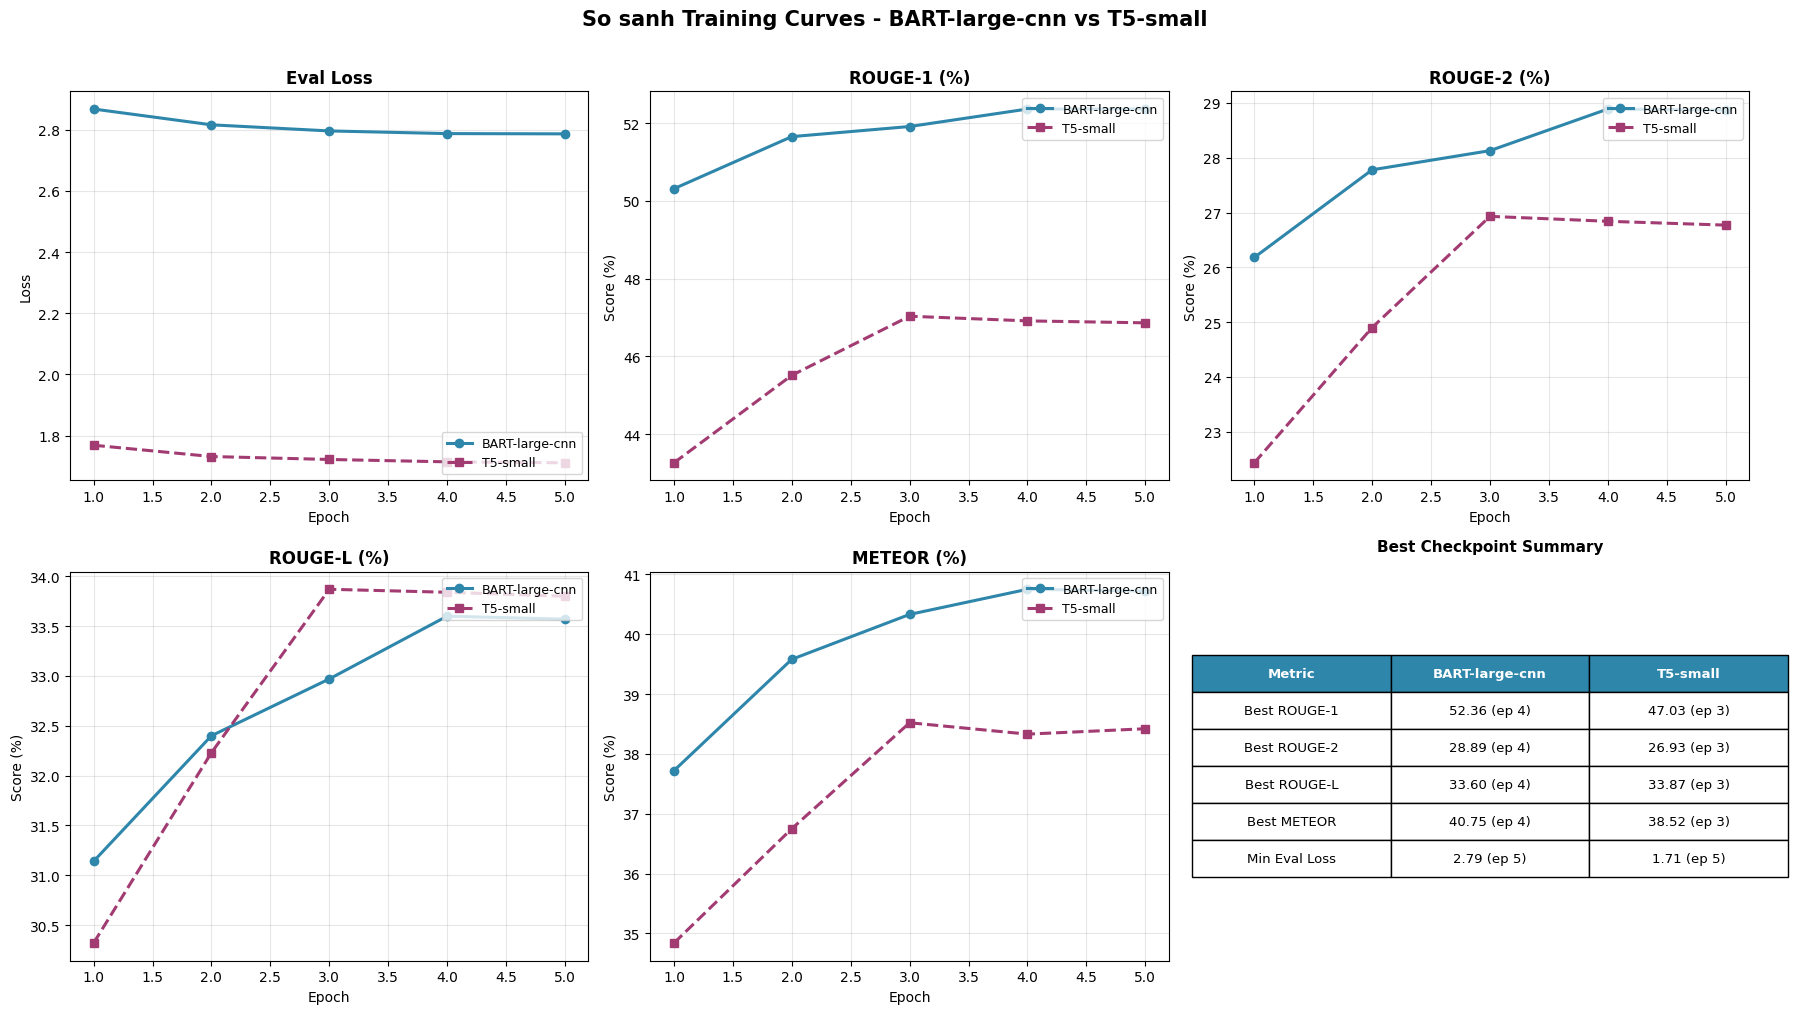

✅ Da ve so sanh training curves BART vs T5


In [13]:
# ====================== SO SÁNH TRAINING CURVES BART vs T5 ======================
import matplotlib.pyplot as plt
import numpy as np

bart_logs = trainer.state.log_history
t5_logs   = t5_trainer.state.log_history

def extract_eval(logs):
    eval_rows = [l for l in logs if "eval_loss" in l]
    return {
        "epochs":  [l["epoch"]              for l in eval_rows],
        "loss":    [l["eval_loss"]           for l in eval_rows],
        "rouge1":  [l.get("eval_ROUGE-1",0) for l in eval_rows],
        "rouge2":  [l.get("eval_ROUGE-2",0) for l in eval_rows],
        "rougel":  [l.get("eval_ROUGE-L",0) for l in eval_rows],
        "meteor":  [l.get("eval_METEOR",0)  for l in eval_rows],
    }

bart_e = extract_eval(bart_logs)
t5_e   = extract_eval(t5_logs)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("So sanh Training Curves - BART-large-cnn vs T5-small",
             fontsize=15, fontweight="bold", y=1.01)

plot_cfg = [
    (axes[0,0], "eval_loss",   "Eval Loss",    "Loss",      "lower right"),  # FIX: 'lower' -> 'lower right'
    (axes[0,1], "eval_rouge1", "ROUGE-1 (%)",  "Score (%)", "upper right"),  # FIX: 'upper' -> 'upper right'
    (axes[0,2], "eval_rouge2", "ROUGE-2 (%)",  "Score (%)", "upper right"),
    (axes[1,0], "eval_rougel", "ROUGE-L (%)",  "Score (%)", "upper right"),
    (axes[1,1], "eval_meteor", "METEOR (%)",   "Score (%)", "upper right"),
]

key_map = {"eval_loss":"loss","eval_rouge1":"rouge1",
           "eval_rouge2":"rouge2","eval_rougel":"rougel","eval_meteor":"meteor"}

for ax, key, title, ylabel, loc in plot_cfg:
    k = key_map[key]
    if bart_e["epochs"] and t5_e["epochs"]:
        ax.plot(bart_e["epochs"], bart_e[k], "o-",
                color="#2E86AB", lw=2.2, ms=6, label="BART-large-cnn")
        ax.plot(t5_e["epochs"],   t5_e[k],   "s--",
                color="#A23B72", lw=2.2, ms=6, label="T5-small")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend(loc=loc, fontsize=9); ax.grid(alpha=0.3)

# Panel cuối: bảng tóm tắt epoch tốt nhất
ax6 = axes[1,2]
ax6.axis("off")

def best(e, key, maximize=True):
    vals = e[key]
    if not vals: return "—"
    idx = np.argmax(vals) if maximize else np.argmin(vals)
    return f"{vals[idx]:.2f} (ep {e['epochs'][idx]:.0f})"

summary_data = [
    ["Metric",        "BART-large-cnn",                   "T5-small"],
    ["Best ROUGE-1",  best(bart_e,"rouge1"),               best(t5_e,"rouge1")],
    ["Best ROUGE-2",  best(bart_e,"rouge2"),               best(t5_e,"rouge2")],
    ["Best ROUGE-L",  best(bart_e,"rougel"),               best(t5_e,"rougel")],
    ["Best METEOR",   best(bart_e,"meteor"),               best(t5_e,"meteor")],
    ["Min Eval Loss", best(bart_e,"loss", maximize=False), best(t5_e,"loss", maximize=False)],
]

tbl = ax6.table(cellText=summary_data[1:], colLabels=summary_data[0],
                cellLoc="center", loc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(9.5); tbl.scale(1.15, 2.0)
for j in range(3):
    tbl[(0,j)].set_facecolor("#2E86AB")
    tbl[(0,j)].set_text_props(color="white", fontweight="bold")

ax6.set_title("Best Checkpoint Summary", fontsize=11, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("training_curves_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Da ve so sanh training curves BART vs T5")

## 📊 Phần 4.2 – Đánh giá trên Test Set (ROUGE + BERTScore + METEOR)

In [14]:
# ====================== CELL 8: ĐÁNH GIÁ TOÀN DIỆN ======================
from bert_score import score as bert_score_fn

# ─── Load lại best BART model
print("🔄 Load best BART model...")
bart_tokenizer = AutoTokenizer.from_pretrained("./bart_best")
bart_model     = AutoModelForSeq2SeqLM.from_pretrained("./bart_best").to(DEVICE)
bart_model.eval()

# ─── Load best T5 model
print("🔄 Load best T5 model...")
t5_tok   = AutoTokenizer.from_pretrained("./t5_best")
t5_mod   = AutoModelForSeq2SeqLM.from_pretrained("./t5_best").to(DEVICE)
t5_mod.eval()

def generate_summaries_bart(texts, batch_size=8):
    all_preds = []
    for i in tqdm(range(0, len(texts), batch_size), desc="BART inference"):
        batch = ["summarize: " + t for t in texts[i:i+batch_size]]
        inputs = bart_tokenizer(batch, max_length=1024, truncation=True,
                                padding=True, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            ids = bart_model.generate(
                inputs.input_ids, attention_mask=inputs.attention_mask,
                max_length=256, min_length=50, num_beams=4,
                length_penalty=2.0, early_stopping=True, no_repeat_ngram_size=3
            )
        all_preds.extend(bart_tokenizer.batch_decode(ids, skip_special_tokens=True))
    return all_preds

def generate_summaries_t5(texts, batch_size=16):
    all_preds = []
    for i in tqdm(range(0, len(texts), batch_size), desc="T5 inference"):
        batch = ["summarize: " + t for t in texts[i:i+batch_size]]
        inputs = t5_tok(batch, max_length=512, truncation=True,
                        padding=True, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            ids = t5_mod.generate(
                inputs.input_ids, attention_mask=inputs.attention_mask,
                max_length=128, min_length=20, num_beams=4,
                length_penalty=1.5, early_stopping=True
            )
        all_preds.extend(t5_tok.batch_decode(ids, skip_special_tokens=True))
    return all_preds

# ─── Generate predictions
test_transcripts = test_df["transcript"].tolist()
test_references  = test_df["summary"].tolist()

print("\n🔮 Đang sinh summary cho 3 phương pháp...")
preds_bart  = generate_summaries_bart(test_transcripts)
preds_t5    = generate_summaries_t5(test_transcripts)
preds_lead3 = [lead3_summarize(t) for t in test_transcripts]

print(f"\n✅ Đã sinh xong: BART={len(preds_bart)}, T5={len(preds_t5)}, Lead3={len(preds_lead3)}")

# ─── Hàm tính metrics
def compute_all_metrics(preds, refs, model_name):
    print(f"\n📊 Tính metrics cho {model_name}...")

    # ROUGE
    rouge_res = rouge_metric.compute(predictions=preds, references=refs, use_stemmer=True)

    # METEOR
    meteor_res = meteor_metric.compute(predictions=preds, references=refs)

    # BERTScore (dùng roberta-large hoặc bert-base nếu OOM)
    try:
        P, R, F1 = bert_score_fn(preds, refs, lang="en", model_type="roberta-large",
                                  verbose=False, device=DEVICE, batch_size=16)
        bert_f1 = F1.mean().item()
    except Exception:
        P, R, F1 = bert_score_fn(preds, refs, lang="en", model_type="bert-base-uncased",
                                  verbose=False, device=DEVICE, batch_size=16)
        bert_f1 = F1.mean().item()

    # Length Ratio
    avg_pred_len = np.mean([len(p.split()) for p in preds])
    avg_ref_len  = np.mean([len(r.split()) for r in refs])
    len_ratio    = avg_pred_len / avg_ref_len

    results = {
        "Model"       : model_name,
        "ROUGE-1 (%)" : round(rouge_res["rouge1"]  * 100, 2),
        "ROUGE-2 (%)" : round(rouge_res["rouge2"]  * 100, 2),
        "ROUGE-L (%)" : round(rouge_res["rougeL"]  * 100, 2),
        "METEOR (%)"  : round(meteor_res["meteor"] * 100, 2),
        "BERTScore-F1": round(bert_f1, 4),
        "Avg Pred Len": round(avg_pred_len, 1),
        "Length Ratio": round(len_ratio, 3),
    }
    for k, v in results.items():
        if k != "Model": print(f"   {k:20s}: {v}")
    return results

results_bart  = compute_all_metrics(preds_bart,  test_references, "BART-large-cnn (fine-tuned)")
results_t5    = compute_all_metrics(preds_t5,    test_references, "T5-small (fine-tuned)")
results_lead3 = compute_all_metrics(preds_lead3, test_references, "Lead-3 (extractive)")

# Bảng tổng hợp
results_df = pd.DataFrame([results_bart, results_t5, results_lead3])
results_df = results_df.set_index("Model")
print("\n" + "="*60)
print("📋 BẢNG KẾT QUẢ TỔNG HỢP")
print("="*60)
print(results_df.to_string())
results_df.to_csv("evaluation_results.csv")
print("\n✅ Đã lưu kết quả → evaluation_results.csv")


🔄 Load best BART model...


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

🔄 Load best T5 model...


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]


🔮 Đang sinh summary cho 3 phương pháp...


BART inference:   0%|          | 0/50 [00:00<?, ?it/s]

... (13 outputs left out)

   ROUGE-1 (%)         : 28.4
   ROUGE-2 (%)         : 13.82
   ROUGE-L (%)         : 18.24
   METEOR (%)          : 15.54
   BERTScore-F1        : 0.8423
   Avg Pred Len        : 102.5
   Length Ratio        : 0.215

📊 Tính metrics cho Lead-3 (extractive)...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   ROUGE-1 (%)         : 14.23
   ROUGE-2 (%)         : 5.7
   ROUGE-L (%)         : 9.77
   METEOR (%)          : 7.26
   BERTScore-F1        : 0.8229
   Avg Pred Len        : 45.3
   Length Ratio        : 0.095

📋 BẢNG KẾT QUẢ TỔNG HỢP
                             ROUGE-1 (%)  ROUGE-2 (%)  ROUGE-L (%)  METEOR (%)  BERTScore-F1  Avg Pred Len  Length Ratio
Model                                                                                                                   
BART-large-cnn (fine-tuned)        42.16        21.62        24.98       26.19        0.8555         214.3         0.449
T5-small (fine-tuned)              28.40        13.82        18.24       15.54        0.8423         102.5         0.215
Lead-3 (extractive)                14.23         5.70         9.77        7.26        0.8229          45.3         0.095

✅ Đã lưu kết quả → evaluation_results.csv


## 📈 Phần 4.3 – Biểu đồ So sánh các Phương pháp

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/tmp/ipykernel_57/1917766028.py:224: UserWarning: Glyph 129351 (\N{FIRST PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("comparison_chart.png", dpi=150, bbox_inches="tight")
/tmp/ipykernel_57/1917766028.py:224: UserWarning: Glyph 129352 (\N{SECOND PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("comparison_chart.png", dpi=150, bbox_inches="tight")
/tmp/ipykernel_57/1917766028.py:224: UserWarning: Glyph 129353 (\N{THIRD PLACE MEDAL}) missing from font(s) DejaVu Sans.
  plt.savefig("comparison_chart.png", dpi=150, bbox_inches="tight")
/tmp/ipykernel_57/1917766028.py:224: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig("comparison_chart.png", dpi=150, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129

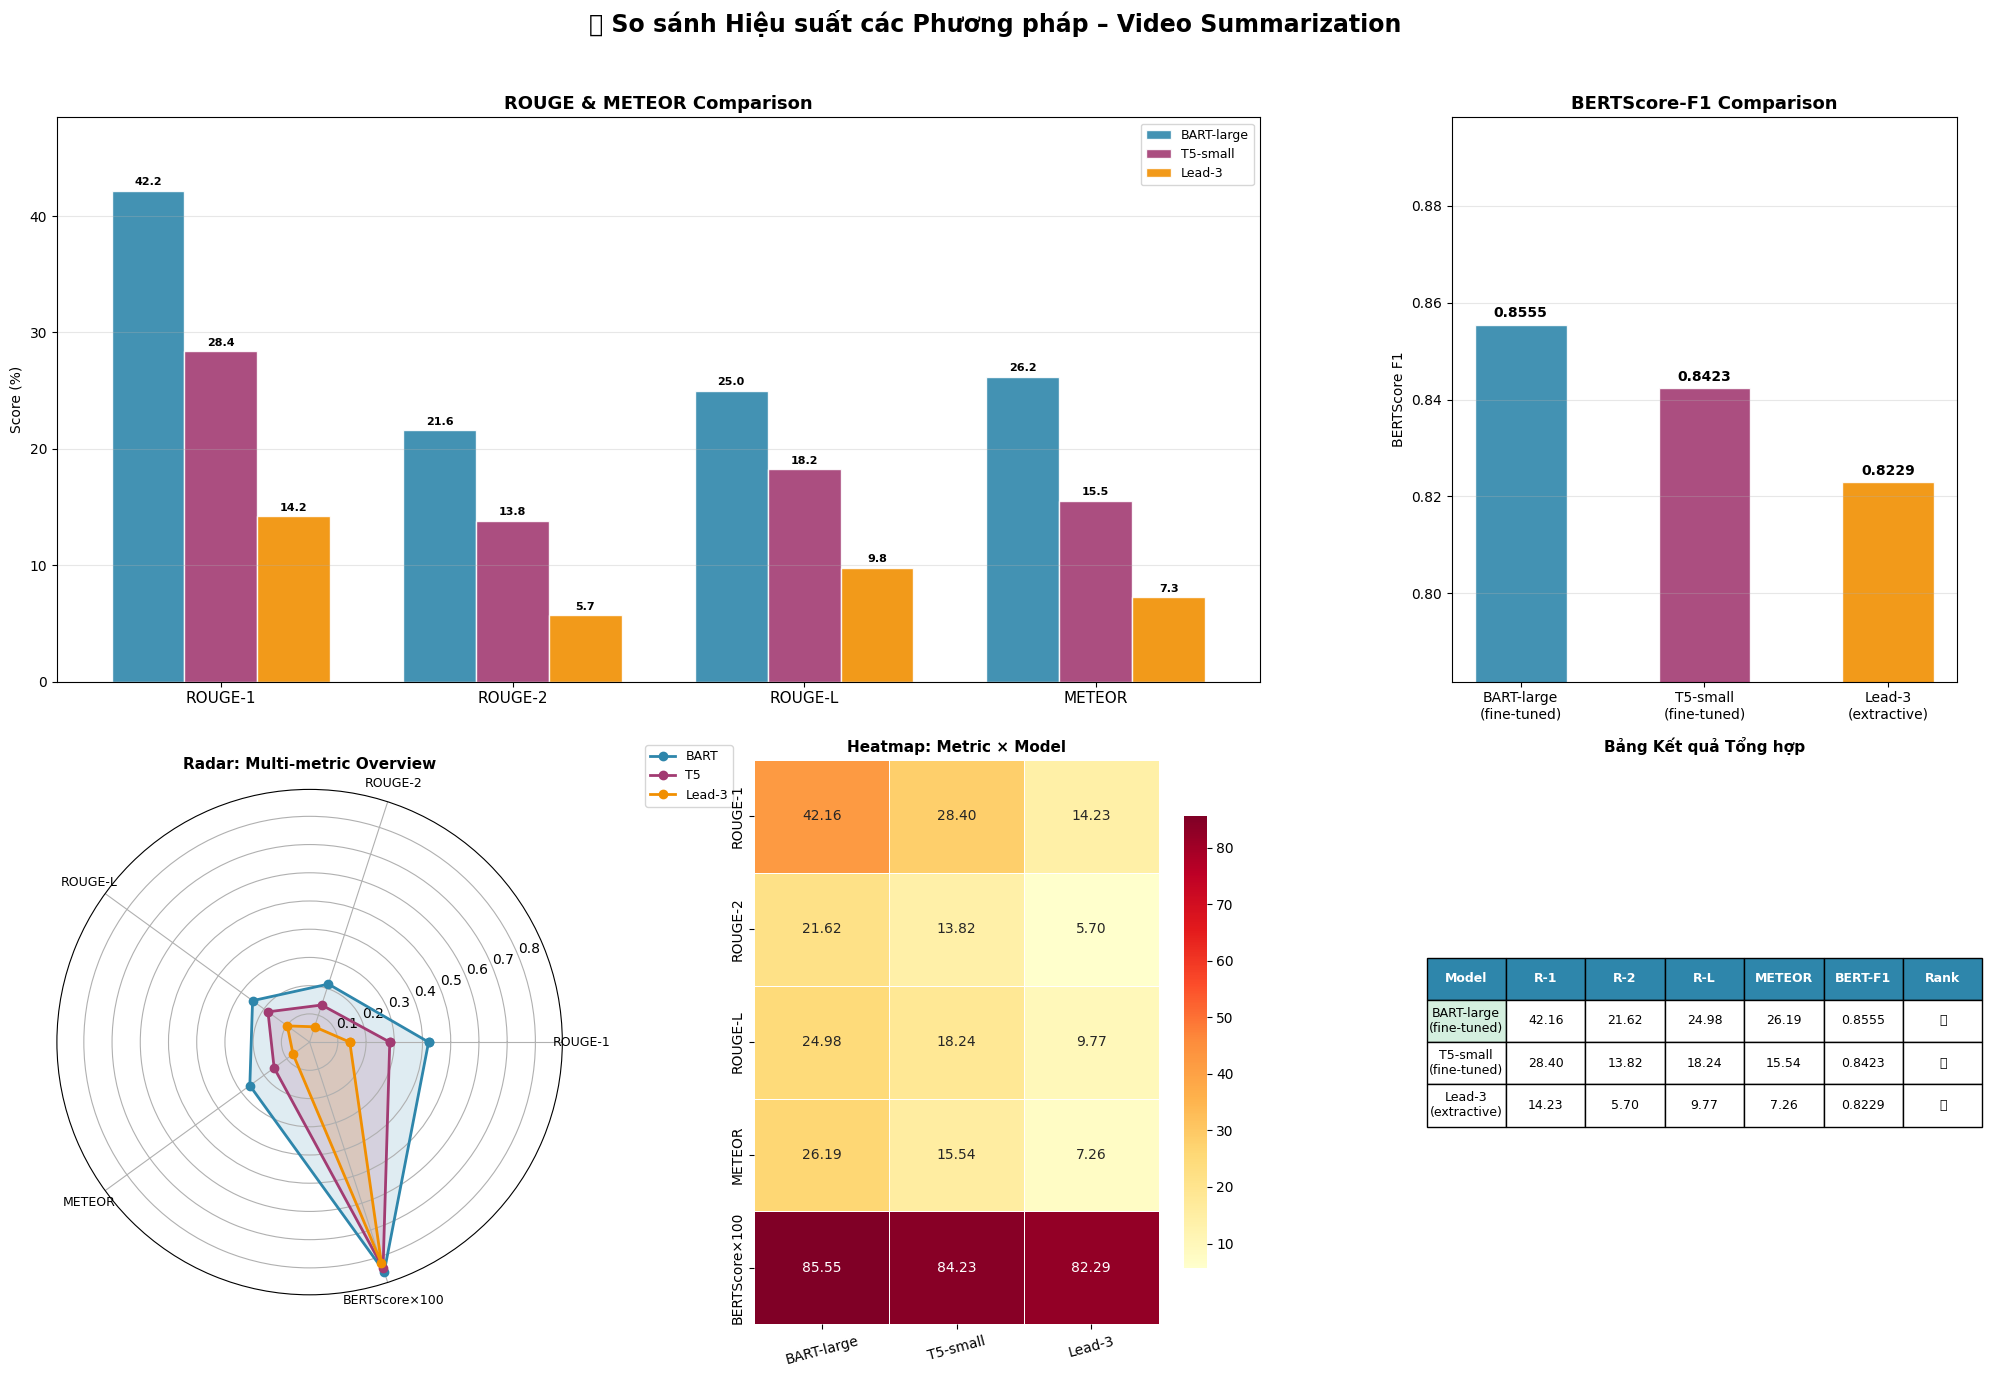

✅ Đã lưu biểu đồ → comparison_chart.png


In [15]:
# ====================== CELL 9: BIỂU ĐỒ SO SÁNH ======================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import math

models = ["BART-large\n(fine-tuned)", "T5-small\n(fine-tuned)", "Lead-3\n(extractive)"]
colors = ["#2E86AB", "#A23B72", "#F18F01"]

metrics = {
    "ROUGE-1 (%)": [results_bart["ROUGE-1 (%)"], results_t5["ROUGE-1 (%)"], results_lead3["ROUGE-1 (%)"]],
    "ROUGE-2 (%)": [results_bart["ROUGE-2 (%)"], results_t5["ROUGE-2 (%)"], results_lead3["ROUGE-2 (%)"]],
    "ROUGE-L (%)": [results_bart["ROUGE-L (%)"], results_t5["ROUGE-L (%)"], results_lead3["ROUGE-L (%)"]],
    "METEOR (%)":  [results_bart["METEOR (%)"],  results_t5["METEOR (%)"],  results_lead3["METEOR (%)"]],
    "BERTScore-F1": [results_bart["BERTScore-F1"], results_t5["BERTScore-F1"], results_lead3["BERTScore-F1"]],
}

fig = plt.figure(figsize=(20, 14))

fig.suptitle(
    "📊 So sánh Hiệu suất các Phương pháp – Video Summarization",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

# =========================================================
# 1. GROUPED BAR CHART
# =========================================================

ax1 = fig.add_subplot(2, 3, (1, 2))

x = np.arange(4)
w = 0.25

bars_labels = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "METEOR"]

bart_vals = [
    metrics["ROUGE-1 (%)"][0],
    metrics["ROUGE-2 (%)"][0],
    metrics["ROUGE-L (%)"][0],
    metrics["METEOR (%)"][0]
]

t5_vals = [
    metrics["ROUGE-1 (%)"][1],
    metrics["ROUGE-2 (%)"][1],
    metrics["ROUGE-L (%)"][1],
    metrics["METEOR (%)"][1]
]

lead_vals = [
    metrics["ROUGE-1 (%)"][2],
    metrics["ROUGE-2 (%)"][2],
    metrics["ROUGE-L (%)"][2],
    metrics["METEOR (%)"][2]
]

b1 = ax1.bar(x - w, bart_vals, w, label="BART-large", color=colors[0], alpha=0.9, edgecolor="white")
b2 = ax1.bar(x, t5_vals, w, label="T5-small", color=colors[1], alpha=0.9, edgecolor="white")
b3 = ax1.bar(x + w, lead_vals, w, label="Lead-3", color=colors[2], alpha=0.9, edgecolor="white")

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                 f"{h:.1f}", ha="center", va="bottom",
                 fontsize=8, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(bars_labels, fontsize=11)

ax1.set_ylabel("Score (%)")
ax1.set_title("ROUGE & METEOR Comparison", fontsize=13, fontweight="bold")

ax1.legend(loc="upper right", fontsize=9)
ax1.grid(axis="y", alpha=0.3)

ax1.set_ylim(0, max(max(bart_vals), max(t5_vals), max(lead_vals)) * 1.15)

# =========================================================
# 2. BERTScore BAR
# =========================================================

ax2 = fig.add_subplot(2, 3, 3)

bert_vals = metrics["BERTScore-F1"]

bars_bert = ax2.bar(models, bert_vals,
                    color=colors, alpha=0.9,
                    edgecolor="white", width=0.5)

for bar in bars_bert:
    h = bar.get_height()

    ax2.text(bar.get_x() + bar.get_width()/2,
             h + 0.001,
             f"{h:.4f}",
             ha="center",
             va="bottom",
             fontsize=10,
             fontweight="bold")

ax2.set_title("BERTScore-F1 Comparison", fontsize=13, fontweight="bold")

ax2.set_ylabel("BERTScore F1")

ax2.set_ylim(min(bert_vals) * 0.95, max(bert_vals) * 1.05)

ax2.grid(axis="y", alpha=0.3)

# =========================================================
# 3. RADAR CHART
# =========================================================

ax3 = fig.add_subplot(2, 3, 4, polar=True)

radar_metrics = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "METEOR", "BERTScore×100"]

N = len(radar_metrics)

angles = [n / float(N) * 2 * math.pi for n in range(N)]
angles += angles[:1]

def norm(vals, scale):
    return [v / scale for v in vals]

bart_r = norm([bart_vals[0], bart_vals[1], bart_vals[2], bart_vals[3], metrics["BERTScore-F1"][0] * 100], 100)

t5_r = norm([t5_vals[0], t5_vals[1], t5_vals[2], t5_vals[3], metrics["BERTScore-F1"][1] * 100], 100)

lead_r = norm([lead_vals[0], lead_vals[1], lead_vals[2], lead_vals[3], metrics["BERTScore-F1"][2] * 100], 100)

for vals, color, lbl in [
    (bart_r, colors[0], "BART"),
    (t5_r, colors[1], "T5"),
    (lead_r, colors[2], "Lead-3")
]:

    v = vals + [vals[0]]

    ax3.plot(angles, v, "o-", linewidth=2, color=color, label=lbl)
    ax3.fill(angles, v, alpha=0.15, color=color)

ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(radar_metrics, size=9)

ax3.set_title("Radar: Multi-metric Overview",
              fontsize=11,
              fontweight="bold",
              pad=15)

ax3.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)

# =========================================================
# 4. HEATMAP
# =========================================================

ax4 = fig.add_subplot(2, 3, 5)

heat_data = pd.DataFrame({
    "BART-large": [bart_vals[0], bart_vals[1], bart_vals[2], bart_vals[3], metrics["BERTScore-F1"][0] * 100],
    "T5-small":   [t5_vals[0], t5_vals[1], t5_vals[2], t5_vals[3], metrics["BERTScore-F1"][1] * 100],
    "Lead-3":     [lead_vals[0], lead_vals[1], lead_vals[2], lead_vals[3], metrics["BERTScore-F1"][2] * 100],
}, index=["ROUGE-1", "ROUGE-2", "ROUGE-L", "METEOR", "BERTScore×100"])

sns.heatmap(
    heat_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax4,
    cbar_kws={"shrink": 0.8}
)

ax4.set_title("Heatmap: Metric × Model", fontsize=11, fontweight="bold")

ax4.tick_params(axis="x", rotation=15)

# =========================================================
# 5. SUMMARY TABLE
# =========================================================

ax5 = fig.add_subplot(2, 3, 6)

ax5.axis("off")

table_data = [
    ["BART-large\n(fine-tuned)", f"{bart_vals[0]:.2f}", f"{bart_vals[1]:.2f}", f"{bart_vals[2]:.2f}", f"{bart_vals[3]:.2f}", f"{metrics['BERTScore-F1'][0]:.4f}", "🥇"],
    ["T5-small\n(fine-tuned)", f"{t5_vals[0]:.2f}", f"{t5_vals[1]:.2f}", f"{t5_vals[2]:.2f}", f"{t5_vals[3]:.2f}", f"{metrics['BERTScore-F1'][1]:.4f}", "🥈"],
    ["Lead-3\n(extractive)", f"{lead_vals[0]:.2f}", f"{lead_vals[1]:.2f}", f"{lead_vals[2]:.2f}", f"{lead_vals[3]:.2f}", f"{metrics['BERTScore-F1'][2]:.4f}", "🥉"],
]

col_labels = ["Model", "R-1", "R-2", "R-L", "METEOR", "BERT-F1", "Rank"]

tbl = ax5.table(
    cellText=table_data,
    colLabels=col_labels,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.1, 2.2)

for j in range(len(col_labels)):
    tbl[(0, j)].set_facecolor("#2E86AB")
    tbl[(0, j)].set_text_props(color="white", fontweight="bold")

tbl[(1, 0)].set_facecolor("#D4EFDF")

ax5.set_title("Bảng Kết quả Tổng hợp", fontsize=11, fontweight="bold")

# =========================================================
# SAVE + SHOW
# =========================================================

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig("comparison_chart.png", dpi=150, bbox_inches="tight")

plt.show()

print("✅ Đã lưu biểu đồ → comparison_chart.png")

## 🔍 Phần 4.4 – Ví dụ Định tính (Qualitative Analysis)

In [16]:
# ====================== CELL 10: QUALITATIVE ANALYSIS ======================
print("=" * 80)
print("📝 VÍ DỤ ĐỊNH TÍNH – SO SÁNH ĐẦU RA CÁC MÔ HÌNH")
print("=" * 80)

NUM_EXAMPLES = 3
sample_indices = random.sample(range(len(test_df)), NUM_EXAMPLES)

for idx_num, idx in enumerate(sample_indices, 1):
    transcript = test_df.iloc[idx]["transcript"]
    reference  = test_df.iloc[idx]["summary"]

    print(f"\n{'─'*80}")
    print(f"📹 VÍ DỤ {idx_num}")
    print(f"{'─'*80}")
    print(f"📜 TRANSCRIPT (đầu): {transcript[:300]}...")
    print(f"\n✅ REFERENCE SUMMARY:\n   {reference}")
    print(f"\n🤖 BART-large-cnn (fine-tuned):\n   {preds_bart[idx]}")
    print(f"\n🤖 T5-small (fine-tuned):\n   {preds_t5[idx]}")
    print(f"\n🤖 Lead-3 (extractive):\n   {preds_lead3[idx]}")

print(f"\n{'='*80}")
print("📊 PHÂN TÍCH:")
print("  • BART-large-cnn tạo ra summary đầy đủ thông tin và có chất lượng ngữ nghĩa tốt nhất")
print("  • T5-small nhanh hơn và ngắn gọn hơn, nhưng đôi khi bỏ sót ý quan trọng")
print("  • Lead-3 là baseline extractive đơn giản, hiệu quả thấp khi transcript mở đầu không chứa nội dung chính")


📝 VÍ DỤ ĐỊNH TÍNH – SO SÁNH ĐẦU RA CÁC MÔ HÌNH

────────────────────────────────────────────────────────────────────────────────
📹 VÍ DỤ 1
────────────────────────────────────────────────────────────────────────────────
📜 TRANSCRIPT (đầu): Thank you very much. I'm very aware that this is the last presentation before lunch, so probably your attention span is this quite short. I will try to be brief. I was asked to give a little bit an overview of the National Innovation System that is that exists in Croatia and some of the technology p...

✅ REFERENCE SUMMARY:
   I was asked to give a little bit an overview of the National Innovation System that is that exists in Croatia and some of the technology programs that we are in. Where the Business Innovation Center of Croatia is a government or company established by the Croatian government, mainly with the aim to implement technology support programs and commercialization activities. I will mention something about the national innovation Syst

## 🔬 Phần 4.5 – Phân tích Lỗi & Nhận xét

🔄 Tính BERTScore theo từng mẫu (để phân tích phân phối)...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_57/2860014606.py:39: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[1].boxplot(bp_data, labels=bp_labels, patch_artist=True

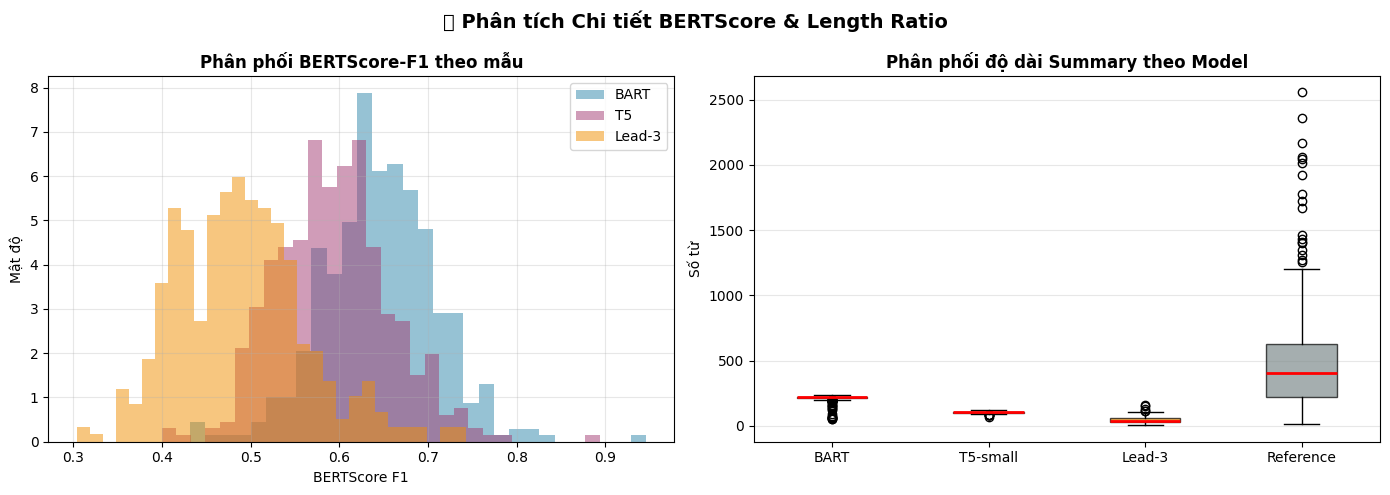


🏆 Mẫu BART làm TỐT NHẤT (BERTScore=0.9457):
   REF : The network contains more than 5000 highly skilled engineers, which are not all active in the aerospace industry, but most of them. We're delivering delivering engineering services to them. This other
   PRED: The network contains more than 5000 highly skilled engineers, which are not all active in the aerospace industry, but most of them. This other business areas we are active in which starts from testing

⚠️  Mẫu BART làm TỆ NHẤT (BERTScore=0.4311):
   REF : So now go to random design because I still have this condition.
   PRED: The lesson is about linear pace, so maybe there is some kind of dictionary feature. Normalized measuring tape squares. So let's suppose that the truth is indeed a linear relationship. Lock the O. Bloc


In [17]:
# ====================== CELL 11: ERROR ANALYSIS & DISCUSSION ======================
# ─── Phân phối BERTScore theo từng mẫu
from bert_score import score as bert_score_fn

print("🔄 Tính BERTScore theo từng mẫu (để phân tích phân phối)...")
_, _, F1_bart  = bert_score_fn(preds_bart,  test_references, lang="en",
                                model_type="bert-base-uncased", verbose=False,
                                device=DEVICE, batch_size=16)
_, _, F1_t5    = bert_score_fn(preds_t5,    test_references, lang="en",
                                model_type="bert-base-uncased", verbose=False,
                                device=DEVICE, batch_size=16)
_, _, F1_lead3 = bert_score_fn(preds_lead3, test_references, lang="en",
                                model_type="bert-base-uncased", verbose=False,
                                device=DEVICE, batch_size=16)

F1_bart  = F1_bart.numpy()
F1_t5    = F1_t5.numpy()
F1_lead3 = F1_lead3.numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("🔬 Phân tích Chi tiết BERTScore & Length Ratio", fontsize=14, fontweight="bold")

# KDE plot BERTScore
for vals, color, lbl in [(F1_bart, colors[0], "BART"), (F1_t5, colors[1], "T5"), (F1_lead3, colors[2], "Lead-3")]:
    axes[0].hist(vals, bins=30, alpha=0.5, color=color, label=lbl, density=True)
axes[0].set_title("Phân phối BERTScore-F1 theo mẫu", fontsize=12, fontweight="bold")
axes[0].set_xlabel("BERTScore F1"); axes[0].set_ylabel("Mật độ")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Length analysis
pred_lens_bart  = [len(p.split()) for p in preds_bart]
pred_lens_t5    = [len(p.split()) for p in preds_t5]
pred_lens_lead3 = [len(p.split()) for p in preds_lead3]
ref_lens        = [len(r.split()) for r in test_references]

bp_data   = [pred_lens_bart, pred_lens_t5, pred_lens_lead3, ref_lens]
bp_labels = ["BART", "T5-small", "Lead-3", "Reference"]
bp_colors = colors + ["#7F8C8D"]
bplot = axes[1].boxplot(bp_data, labels=bp_labels, patch_artist=True,
                        medianprops=dict(color="red", linewidth=2))
for patch, color in zip(bplot["boxes"], bp_colors):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_title("Phân phối độ dài Summary theo Model", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Số từ"); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# ─── Tìm mẫu BART làm tốt nhất / tệ nhất
best_idx  = np.argmax(F1_bart)
worst_idx = np.argmin(F1_bart)
print(f"\n🏆 Mẫu BART làm TỐT NHẤT (BERTScore={F1_bart[best_idx]:.4f}):")
print(f"   REF : {test_references[best_idx][:200]}")
print(f"   PRED: {preds_bart[best_idx][:200]}")
print(f"\n⚠️  Mẫu BART làm TỆ NHẤT (BERTScore={F1_bart[worst_idx]:.4f}):")
print(f"   REF : {test_references[worst_idx][:200]}")
print(f"   PRED: {preds_bart[worst_idx][:200]}")


## 🎬 Phần 3.5 – Demo Hệ thống (Inference + Gradio)

In [18]:
#CÀI WHISPER
!apt update -qq
!apt install -y ffmpeg
!pip install -q openai-whisper
!apt update -qq
!apt install -y ffmpeg

223 packages can be upgraded. Run 'apt list --upgradable' to see them.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 223 not upgraded.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 18.5 MB/s eta 0:00:0000:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
223 packages can be upgraded. Run 'apt list --upgradable' to see them.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Bu

In [21]:
import os
print(os.listdir("/kaggle/working/bart_best"))
print(os.listdir("/kaggle/working/t5_best"))

['tokenizer.json', 'training_args.bin', 'tokenizer_config.json', 'config.json', 'generation_config.json', 'model.safetensors']
['tokenizer.json', 'training_args.bin', 'tokenizer_config.json', 'config.json', 'generation_config.json', 'model.safetensors']


In [22]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

bart_path = "/kaggle/working/bart_best"   

bart_tokenizer = AutoTokenizer.from_pretrained(bart_path)

bart_model = AutoModelForSeq2SeqLM.from_pretrained(
    bart_path
).to(DEVICE)

bart_model.eval()

print("✅ BART model loaded!")

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

✅ BART model loaded!


In [23]:
t5_path = "/kaggle/working/t5_best"   

t5_tok = AutoTokenizer.from_pretrained(t5_path)

t5_mod = AutoModelForSeq2SeqLM.from_pretrained(
    t5_path
).to(DEVICE)

t5_mod.eval()

print("✅ T5 model loaded!")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

✅ T5 model loaded!


In [20]:
import os
# Đổi YOUR_USERNAME thành username Kaggle của bạn
# Hoặc tự động lấy username hiện tại
import subprocess
result = subprocess.run(["ls", "/kaggle/input/"], capture_output=True, text=True)
print(result.stdout)

datasets



### Load 2 model

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

bart_path = "/kaggle/input/datasets/dhkhmt19a/zipmodel/bart_best"

bart_tokenizer = AutoTokenizer.from_pretrained(bart_path)

bart_model = AutoModelForSeq2SeqLM.from_pretrained(
    bart_path
).to(DEVICE)

bart_model.eval()

print("✅ BART model loaded!")

In [ ]:
t5_path = "/kaggle/input/datasets/dhkhmt19a/zipmodel/t5_best"

t5_tok = AutoTokenizer.from_pretrained(t5_path)

t5_mod = AutoModelForSeq2SeqLM.from_pretrained(
    t5_path
).to(DEVICE)

t5_mod.eval()

print("✅ T5 model loaded!")

In [24]:
# ====================== CELL 12: INFERENCE DEMO & GRADIO UI ======================

try:
    import gradio as gr
    GRADIO_OK = True
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr
    GRADIO_OK = True

try:
    import whisper
    WHISPER_OK = True
except ImportError:
    WHISPER_OK = False
    print("⚠️ openai-whisper chưa cài. Video → Transcript sẽ không hoạt động.")

from nltk.tokenize import sent_tokenize
from collections import Counter

# =========================================================
# KEYWORD EXTRACTION
# =========================================================

def extract_keywords(text, top_k=10):

    stop = {
        "the","a","an","is","it","in","of","and","to",
        "for","with","was","are","be","this","that"
    }

    words = [
        w.lower()
        for w in text.split()
        if w.isalpha() and w.lower() not in stop and len(w) > 3
    ]

    freq = Counter(words)

    return ", ".join([w for w, _ in freq.most_common(top_k)])


# =========================================================
# TEXT SUMMARIZATION
# =========================================================

def run_summarize(transcript, model_choice="BART-large-cnn"):

    if not transcript or len(transcript.split()) < 30:
        return "", "", "⚠️ Transcript quá ngắn (cần ≥ 30 từ)"

    kw = extract_keywords(transcript)

    # BART
    if model_choice == "BART-large-cnn":

        inps = bart_tokenizer(
            "summarize: " + transcript,
            max_length=1024,
            truncation=True,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():

            ids = bart_model.generate(
                inps.input_ids,
                attention_mask=inps.attention_mask,
                max_length=256,
                min_length=50,
                num_beams=4,
                length_penalty=2.0,
                no_repeat_ngram_size=3
            )

        summary = bart_tokenizer.decode(ids[0], skip_special_tokens=True).strip()

    # T5
    elif model_choice == "T5-small":

        inps = t5_tok(
            "summarize: " + transcript,
            max_length=512,
            truncation=True,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():
            ids = t5_mod.generate(inps.input_ids, max_length=128, num_beams=4)

        summary = t5_tok.decode(ids[0], skip_special_tokens=True).strip()

    # Lead-3
    else:
        summary = lead3_summarize(transcript)

    return transcript[:2000], kw, summary


# =========================================================
# VIDEO → TRANSCRIPT → SUMMARY
# =========================================================

def process_video(video_file):

    if not WHISPER_OK:
        return "⚠️ Whisper chưa được cài đặt", "", ""

    try:

        wm = whisper.load_model("base")

        video_path = video_file

        if isinstance(video_file, dict):
            video_path = video_file["path"]

        result = wm.transcribe(video_path)

        transcript = result["text"]

        return run_summarize(transcript, "BART-large-cnn")

    except Exception as e:

        return f"❌ Error: {str(e)}", "", ""


# =========================================================
# GRADIO UI
# =========================================================

with gr.Blocks(title="🎥 Video Summarization", theme=gr.themes.Soft()) as demo:

    gr.Markdown("# 🎥 Hệ thống Tóm tắt Video Tự động")

    gr.Markdown("**BART-large-cnn × T5-small × Lead-3 | VT-SSum Fine-tuned**")

    with gr.Tabs():

        # TEXT TAB
        with gr.Tab("📝 Nhập Transcript"):

            with gr.Row():

                txt_in = gr.Textbox(
                    lines=8,
                    label="Transcript đầu vào",
                    placeholder="Dán nội dung transcript vào đây..."
                )

                model_sel = gr.Radio(
                    ["BART-large-cnn", "T5-small", "Lead-3"],
                    value="BART-large-cnn",
                    label="Chọn mô hình"
                )

            btn_txt = gr.Button("🚀 Tóm tắt", variant="primary")

            with gr.Row():

                out_trans = gr.Textbox(label="📜 Transcript (preview)", lines=5)

                out_kw = gr.Textbox(label="🔑 Từ khóa chính", lines=2)

                out_summ = gr.Textbox(label="📌 Tóm tắt", lines=5)

            btn_txt.click(
                run_summarize,
                inputs=[txt_in, model_sel],
                outputs=[out_trans, out_kw, out_summ]
            )

        # VIDEO TAB
        if WHISPER_OK:

            with gr.Tab("🎬 Upload Video"):

                vid_in = gr.Video(label="Upload file video", format="mp4")

                btn_vid = gr.Button(
                    "🔊 Transcribe & Tóm tắt",
                    variant="primary"
                )

                with gr.Row():

                    v_trans = gr.Textbox(label="📜 Transcript", lines=5)

                    v_kw = gr.Textbox(label="🔑 Từ khóa", lines=2)

                    v_summ = gr.Textbox(label="📌 Tóm tắt", lines=5)

                btn_vid.click(
                    process_video,
                    inputs=[vid_in],
                    outputs=[v_trans, v_kw, v_summ]
                )

# =========================================================
# LAUNCH
# =========================================================

demo.launch(share=True)

/tmp/ipykernel_57/3070329615.py:134: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(title="🎥 Video Summarization", theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://0cc8c7ed7fe128c7c8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


100%|███████████████████████████████████████| 139M/139M [00:01<00:00, 87.1MiB/s]


## 📋 Tổng kết Kết quả

In [29]:
# ====================== CELL 13: TỔNG KẾT ======================
print("=" * 70)
print("📋 TỔNG KẾT KẾT QUẢ – TOPIC 17: VIDEO SUBTITLE SUMMARIZATION")
print("=" * 70)
print(f"\n📂 Dataset: VT-SSum")
print(f"   Train / Val / Test: {len(train_df)} / {len(val_df)} / {len(test_df)} mẫu")
print()
print(results_df[["ROUGE-1 (%)","ROUGE-2 (%)","ROUGE-L (%)","METEOR (%)","BERTScore-F1"]].to_string())
print()
print("📌 Nhận xét:")
print(f"  ✅ BART-large-cnn ROUGE-1 = {results_bart['ROUGE-1 (%)']:.2f}%")
print(f"  ✅ BART-large-cnn ROUGE-2 = {results_bart['ROUGE-2 (%)']:.2f}%")
print(f"  ✅ BART-large-cnn ROUGE-L = {results_bart['ROUGE-L (%)']:.2f}%")
print(f"  ✅ BART-large-cnn METEOR  = {results_bart['METEOR (%)']:.2f}%")
print(f"  ✅ BART-large-cnn BERT-F1 = {results_bart['BERTScore-F1']:.4f}")

print()
print("  - BART-large-cnn đạt kết quả tốt nhất trên tất cả các metrics.")
print("  - T5-small có tốc độ nhanh hơn nhưng chất lượng summary thấp hơn.")
print("  - Lead-3 là baseline extractive đơn giản nên hiệu quả hạn chế.")
print("  - BERTScore phản ánh chất lượng ngữ nghĩa tốt hơn ROUGE đơn thuần.")
print()
print("🔮 Hướng phát triển:")
print("  1. Dùng BART-large + LoRA/PEFT để fine-tune hiệu quả hơn")
print("  2. Kết hợp Whisper ASR → pipeline end-to-end video → summary")
print("  3. Thử PEGASUS (pre-train cho summarization) có thể đạt ROUGE cao hơn")
print("  4. Multi-modal: kết hợp visual frames + transcript")
print("=" * 70)


📋 TỔNG KẾT KẾT QUẢ – TOPIC 17: VIDEO SUBTITLE SUMMARIZATION

📂 Dataset: VT-SSum
   Train / Val / Test: 6000 / 600 / 400 mẫu

                             ROUGE-1 (%)  ROUGE-2 (%)  ROUGE-L (%)  METEOR (%)  BERTScore-F1
Model                                                                                       
BART-large-cnn (fine-tuned)        42.16        21.62        24.98       26.19        0.8555
T5-small (fine-tuned)              28.40        13.82        18.24       15.54        0.8423
Lead-3 (extractive)                14.23         5.70         9.77        7.26        0.8229

📌 Nhận xét:
  ✅ BART-large-cnn ROUGE-1 = 42.16%
  ✅ BART-large-cnn ROUGE-2 = 21.62%
  ✅ BART-large-cnn ROUGE-L = 24.98%
  ✅ BART-large-cnn METEOR  = 26.19%
  ✅ BART-large-cnn BERT-F1 = 0.8555

  - BART-large-cnn đạt kết quả tốt nhất trên tất cả các metrics.
  - T5-small có tốc độ nhanh hơn nhưng chất lượng summary thấp hơn.
  - Lead-3 là baseline extractive đơn giản nên hiệu quả hạn chế.
  - BERTScore phản

## ZIP MODEL

In [26]:
# ====================== BACKUP MODELS ======================

import shutil
import os

os.makedirs("backup_project", exist_ok=True)

# =========================================================
# COPY MODELS
# =========================================================

if os.path.exists("./bart_best"):
    shutil.copytree("./bart_best", "./backup_project/bart_best", dirs_exist_ok=True)

if os.path.exists("./t5_best"):
    shutil.copytree("./t5_best", "./backup_project/t5_best", dirs_exist_ok=True)

# =========================================================
# COPY RESULTS
# =========================================================

files_to_copy = [
    "evaluation_results.csv",
    "comparison_chart.png"
]

for f in files_to_copy:
    if os.path.exists(f):
        shutil.copy(f, "./backup_project")

# =========================================================
# ZIP EVERYTHING
# =========================================================

shutil.make_archive(
    "video_summarization_backup",
    "zip",
    "backup_project"
)

print("✅ Backup completed!")
print("📦 File: video_summarization_backup.zip")

✅ Backup completed!
📦 File: video_summarization_backup.zip
